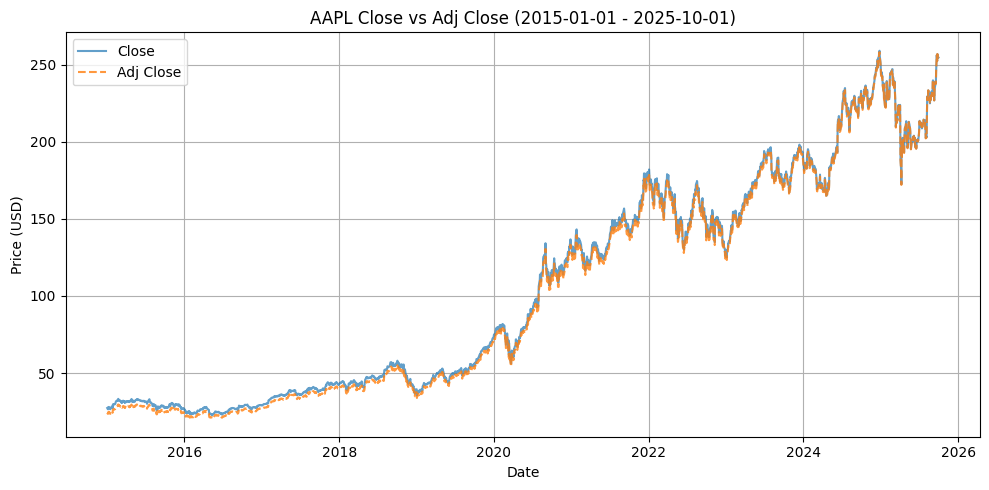

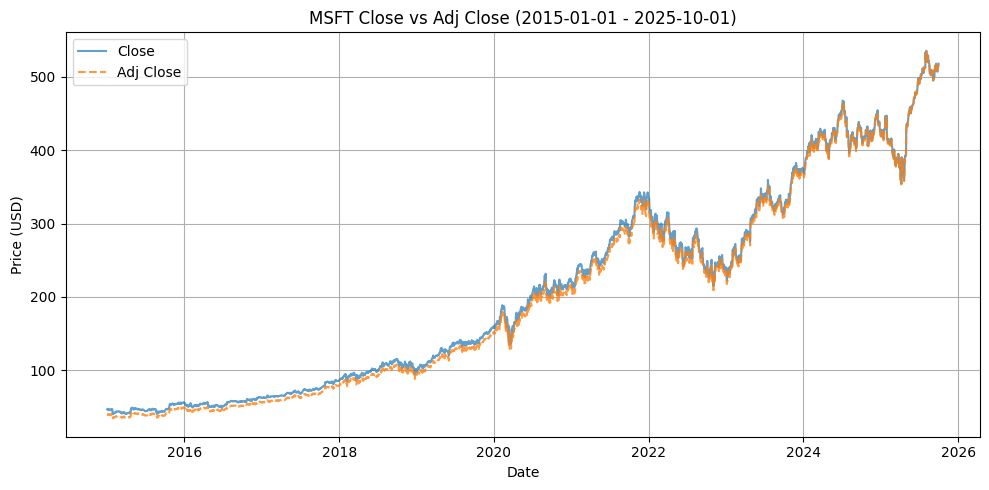

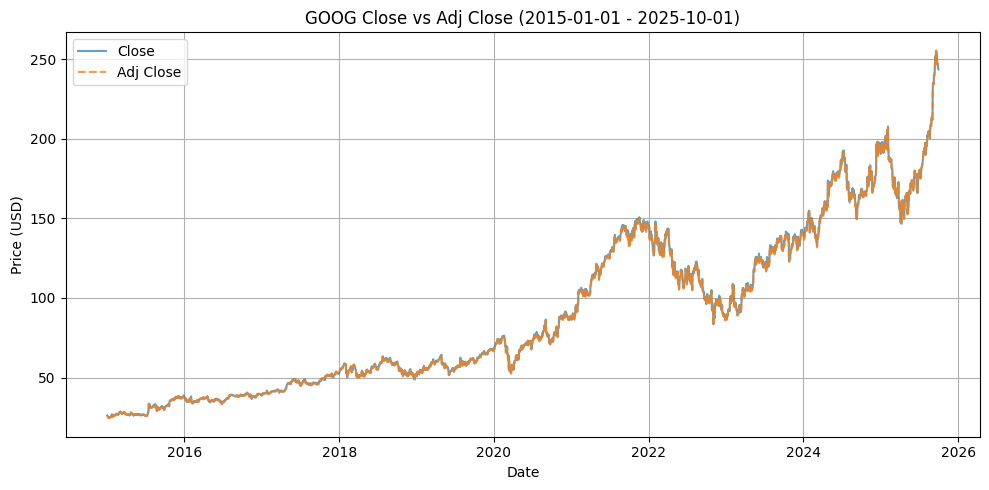

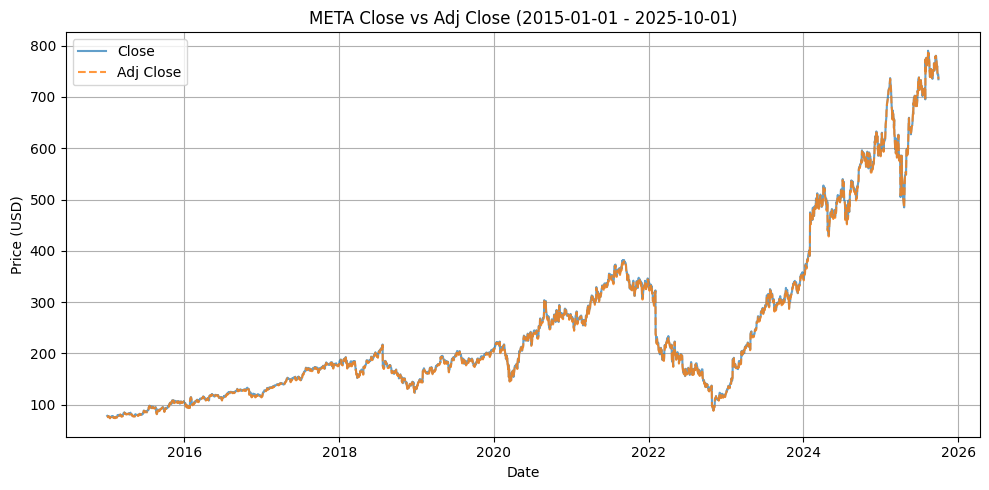

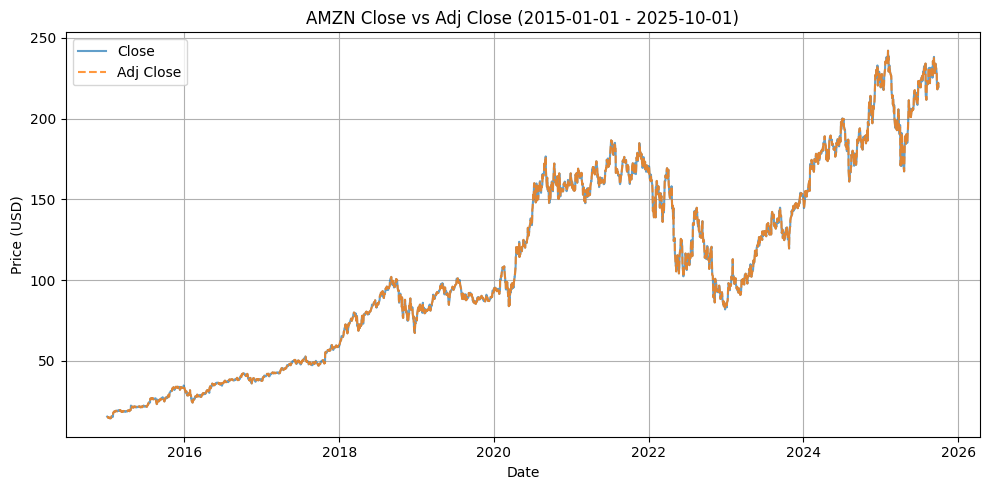

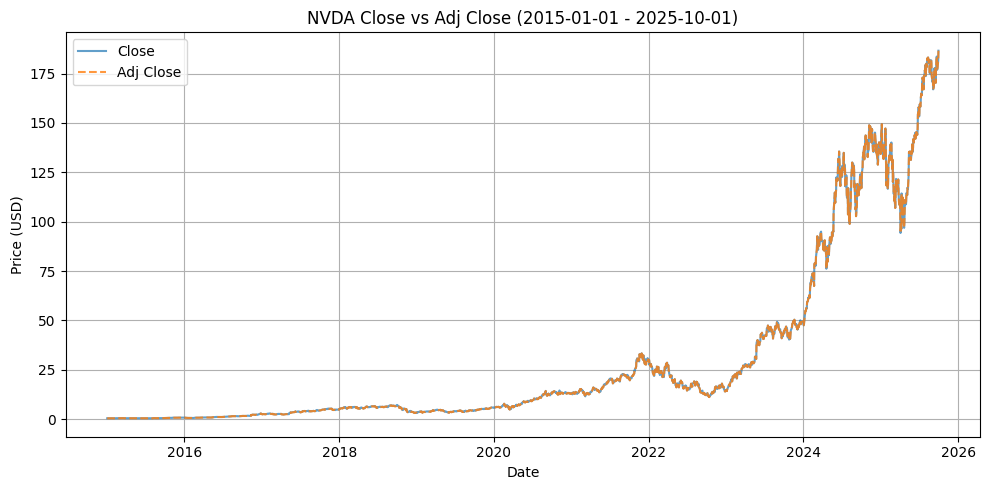

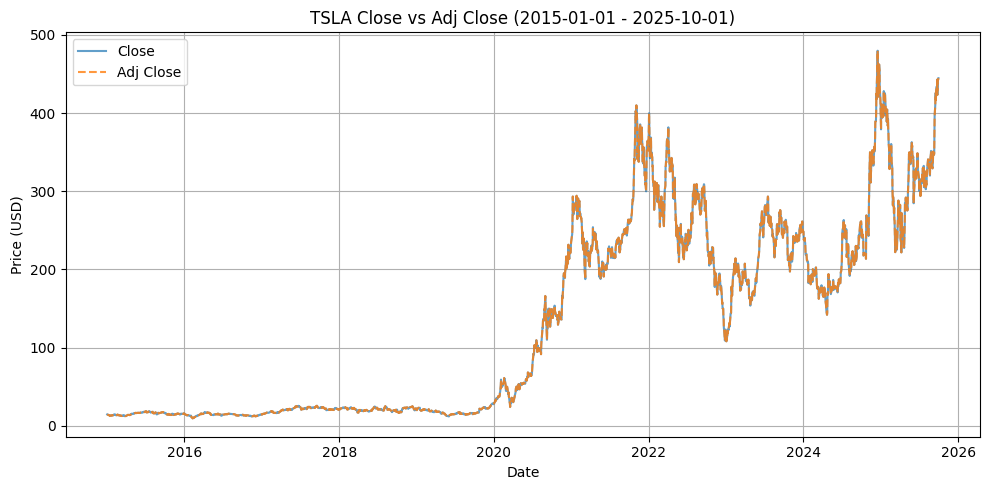

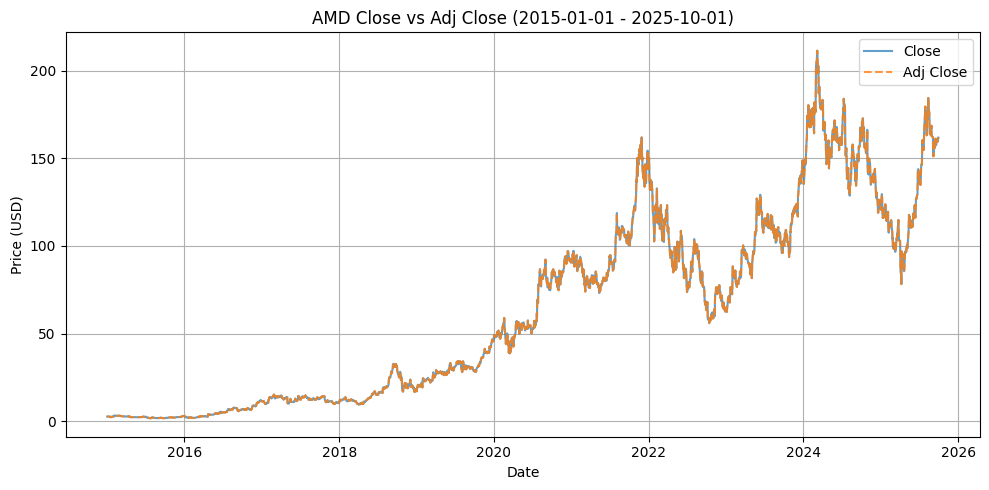

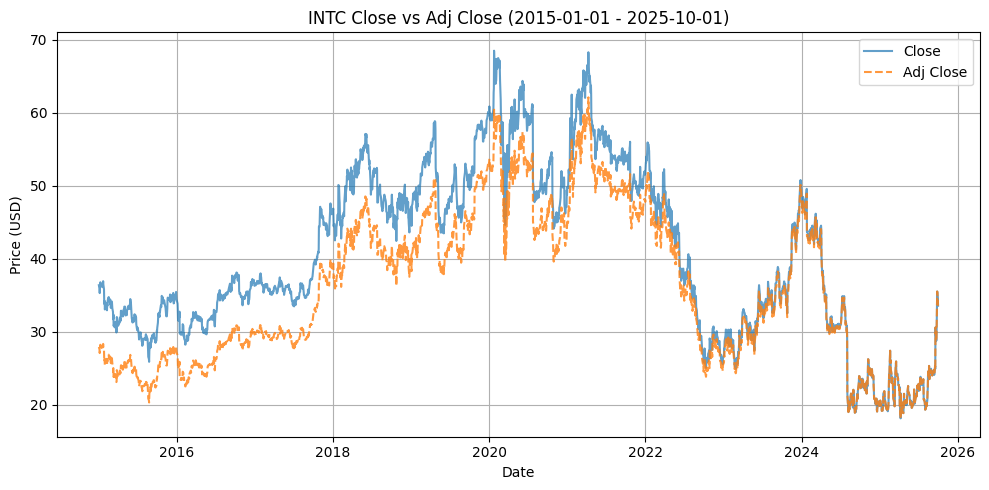

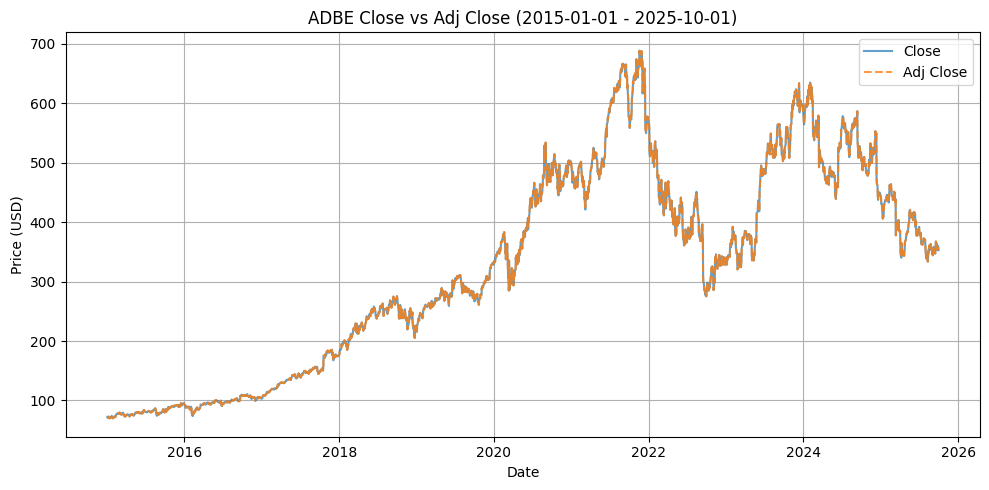

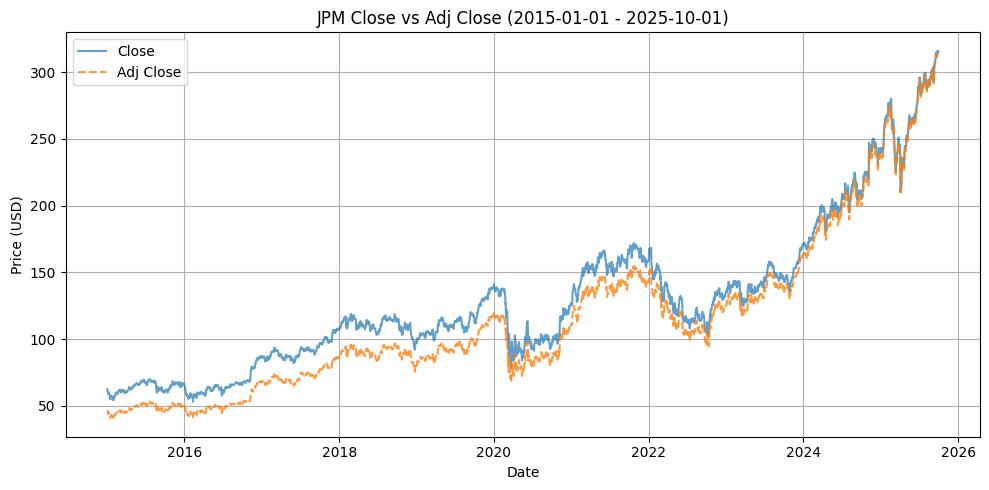

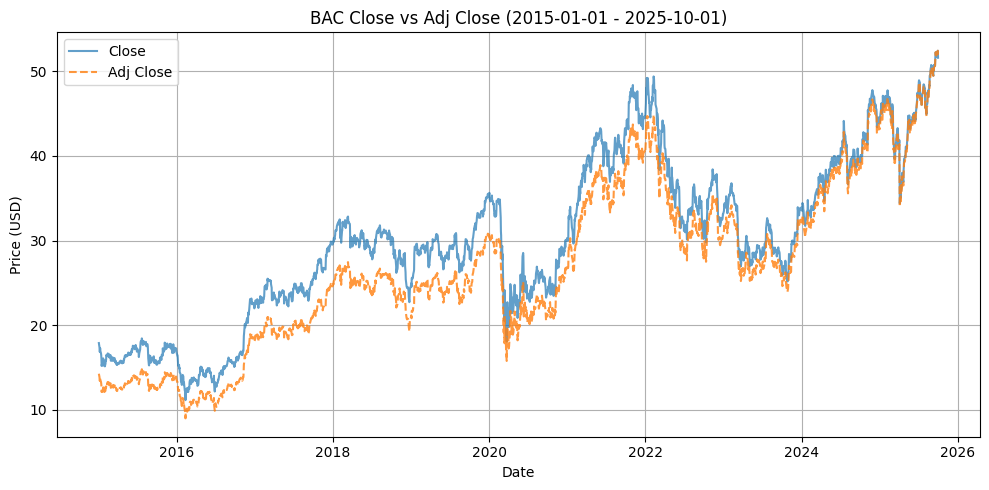

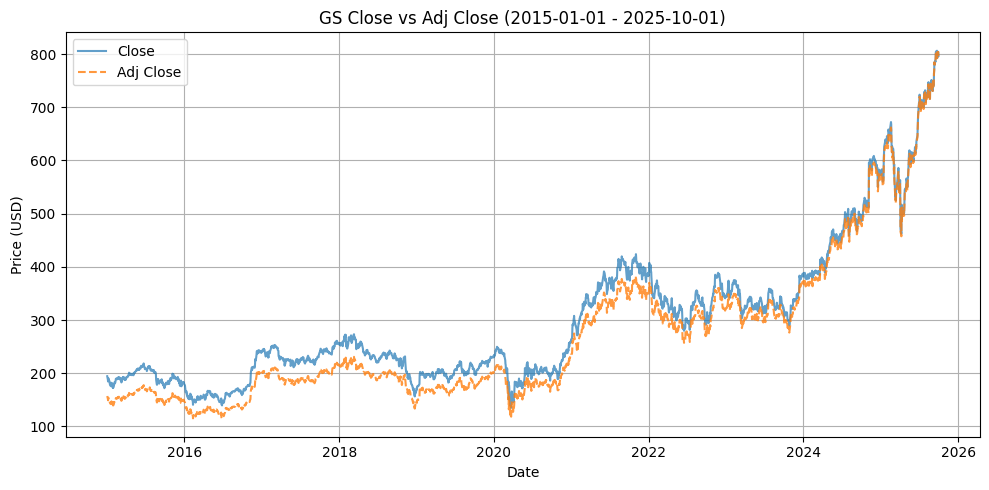

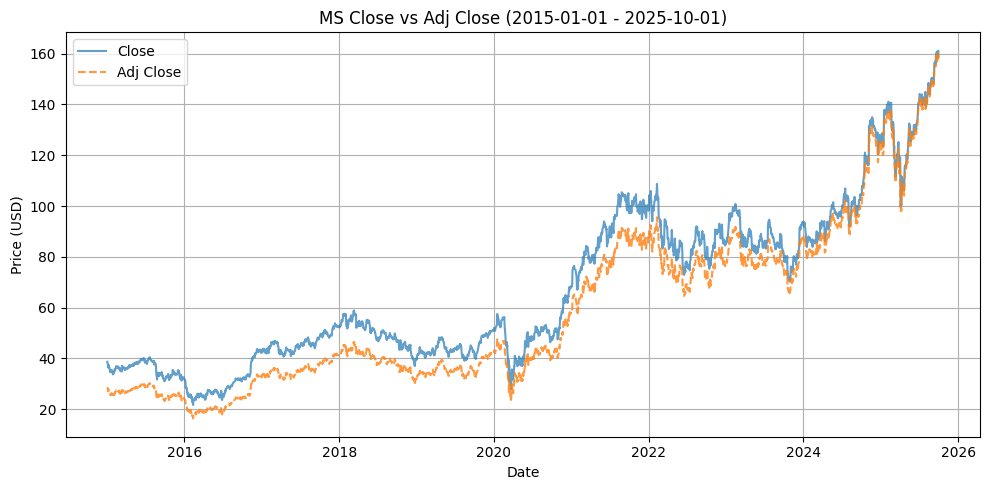

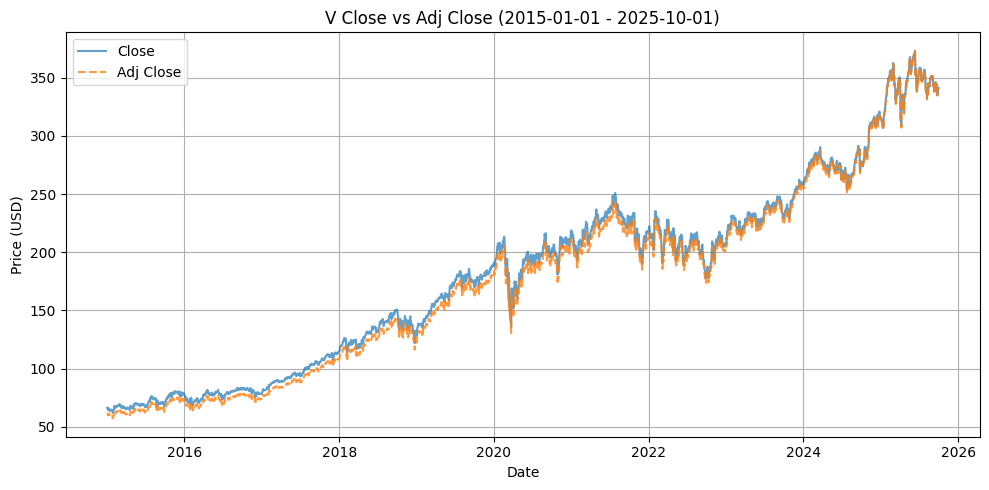

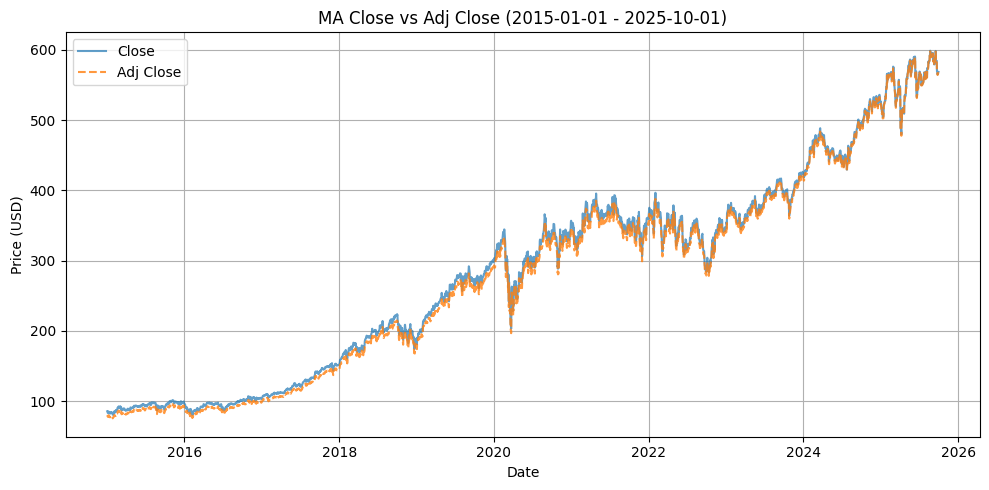

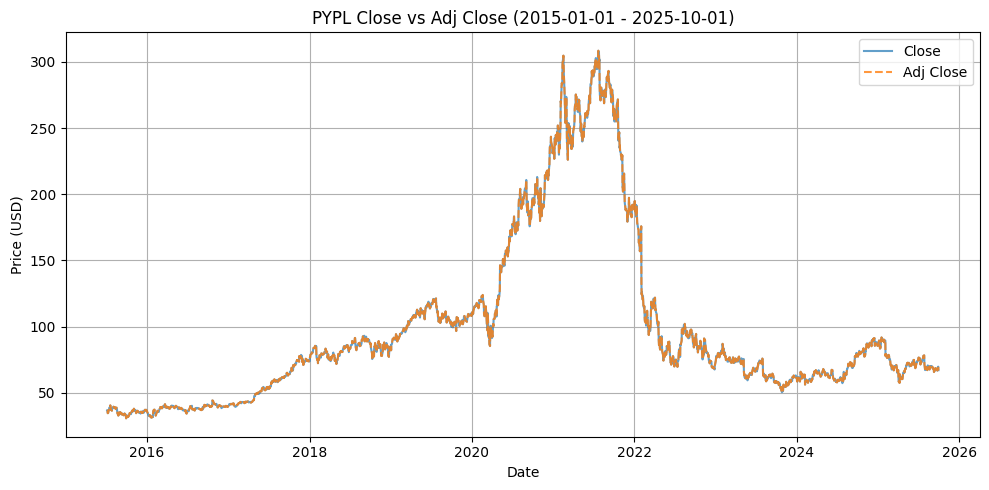

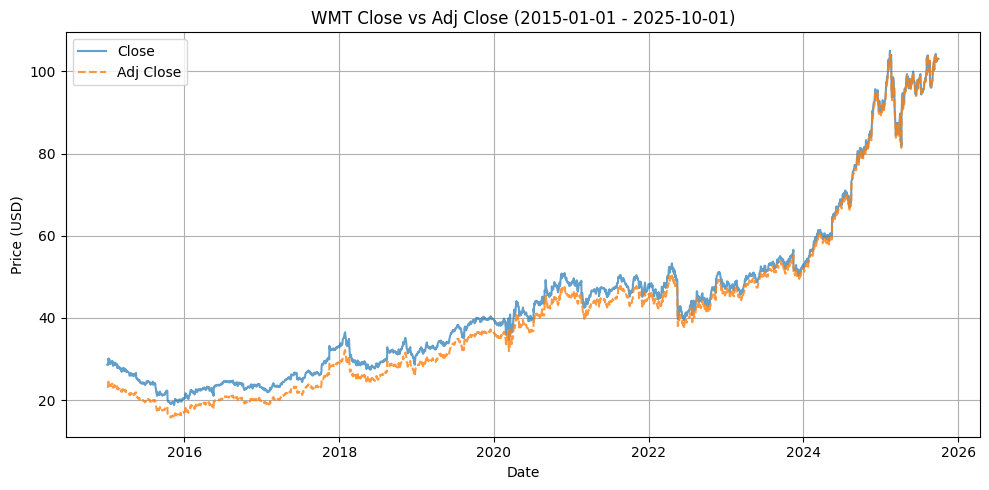

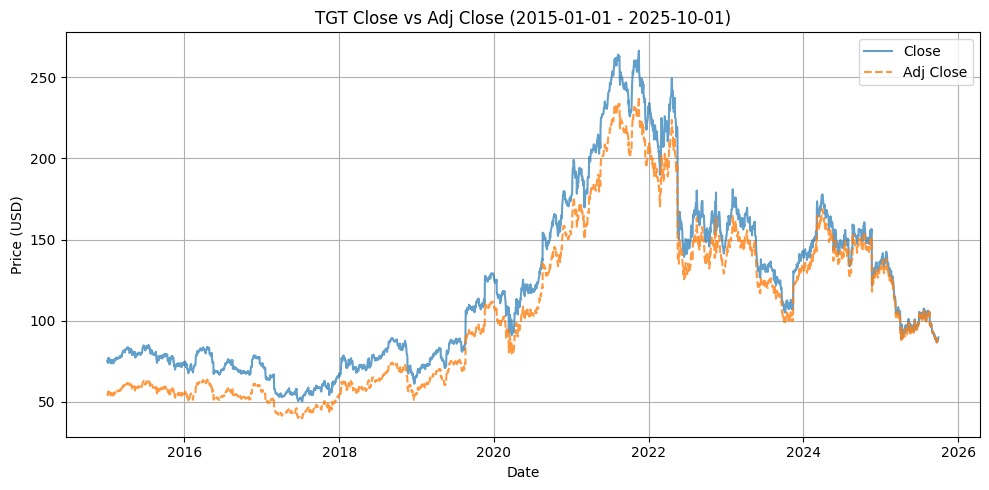

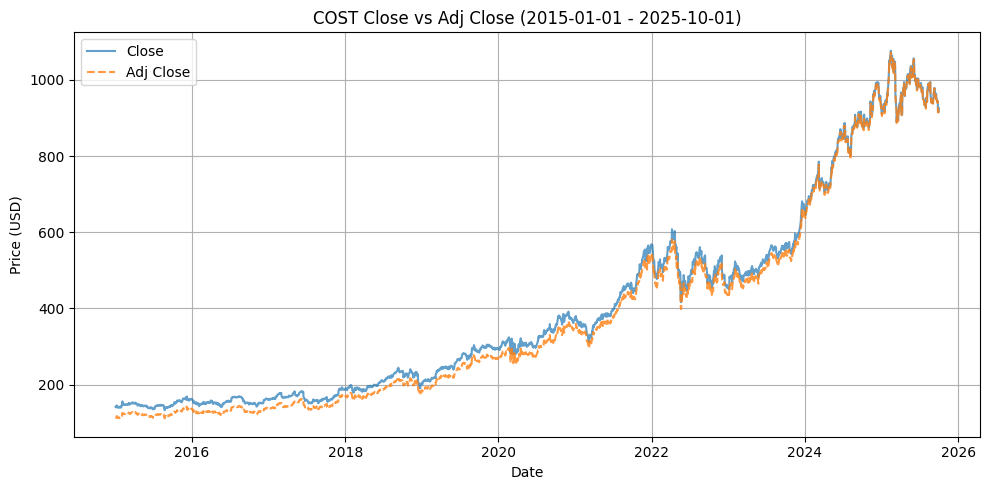

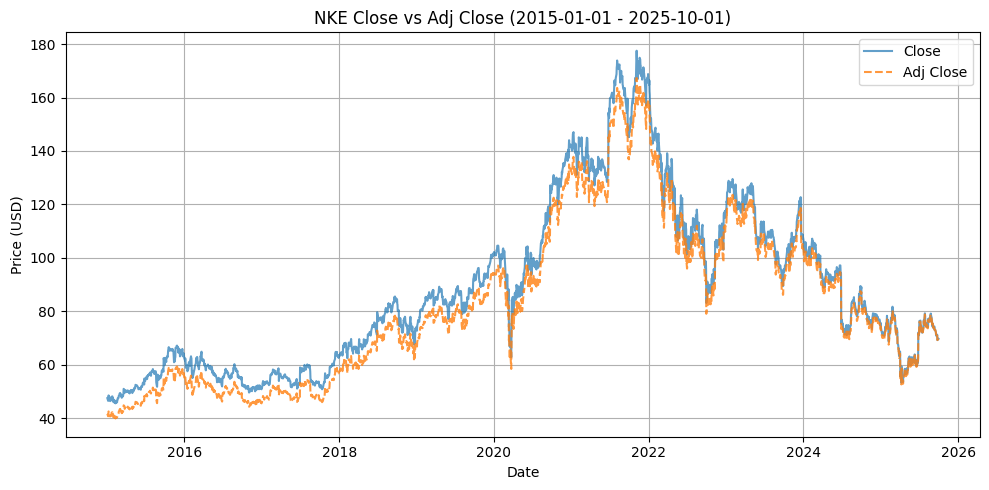

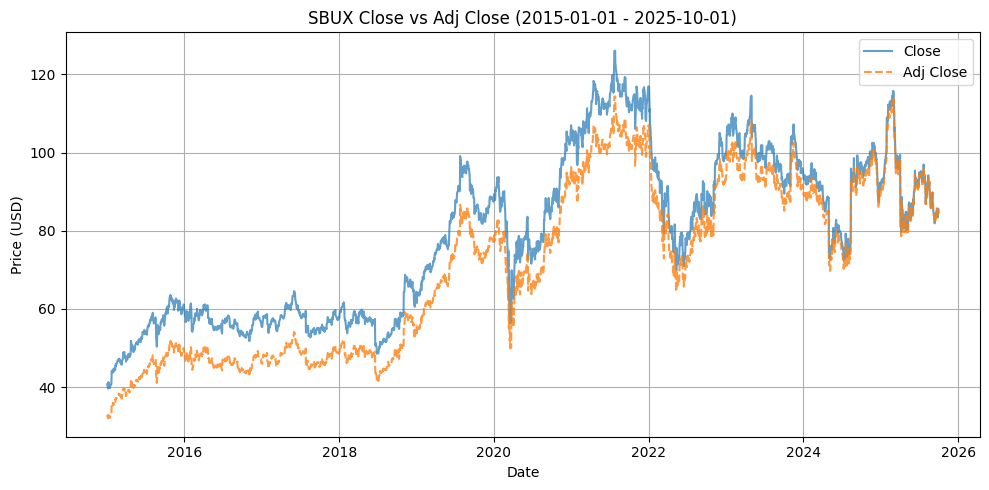

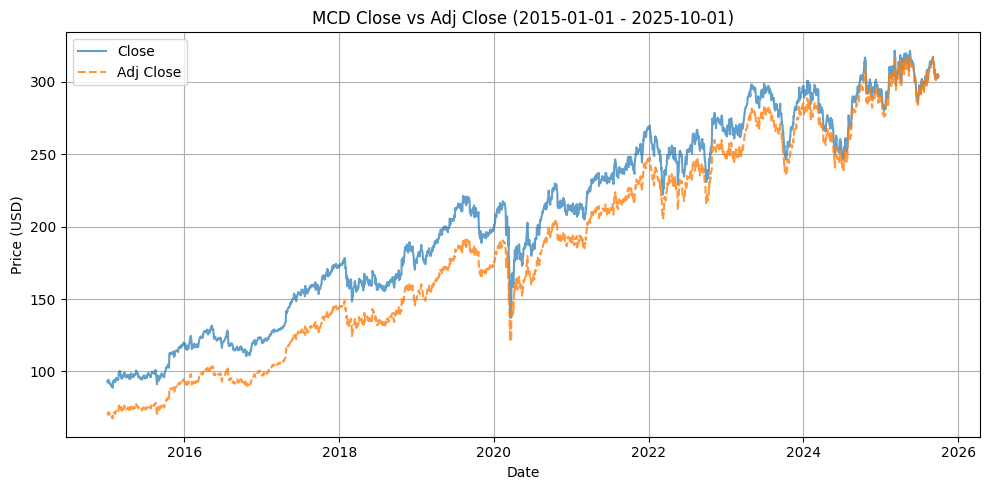

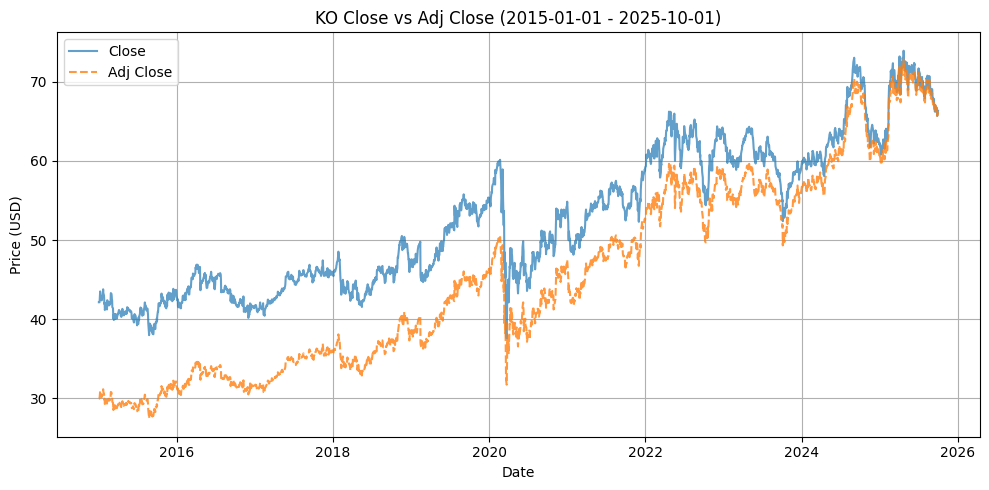

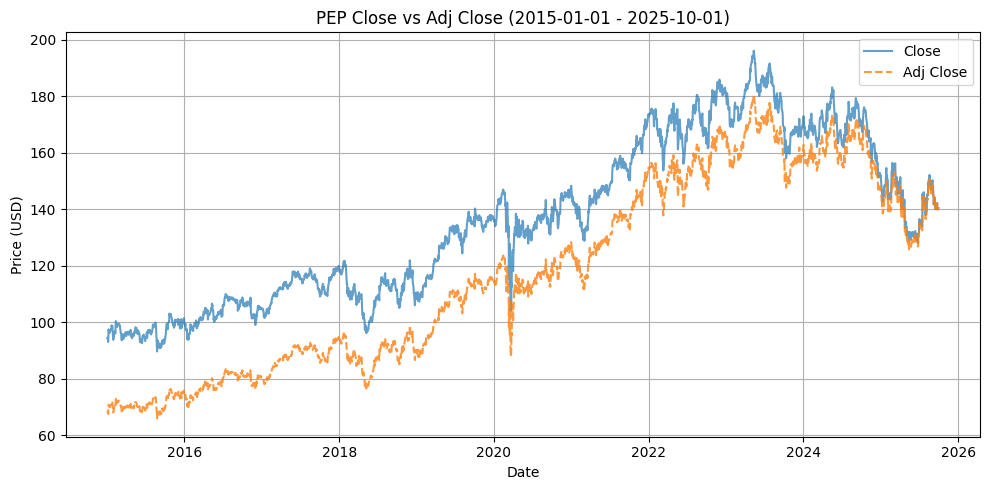

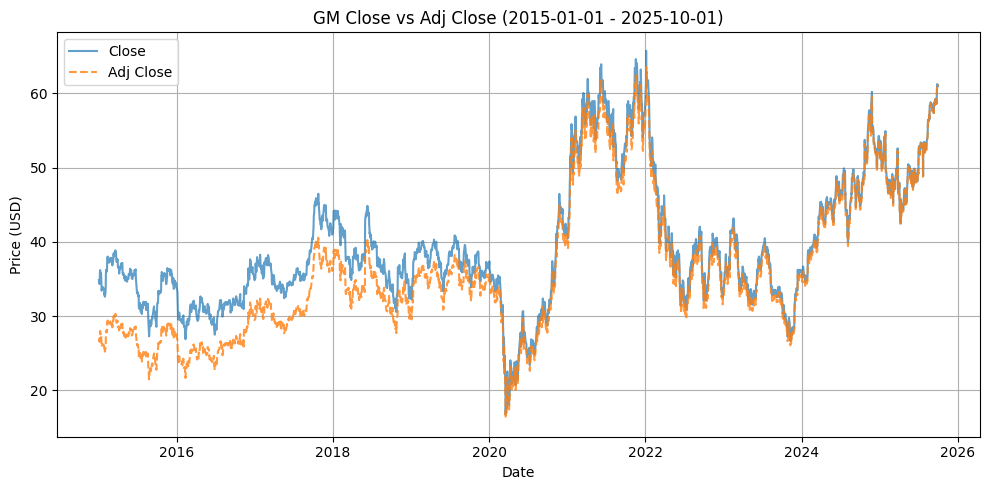

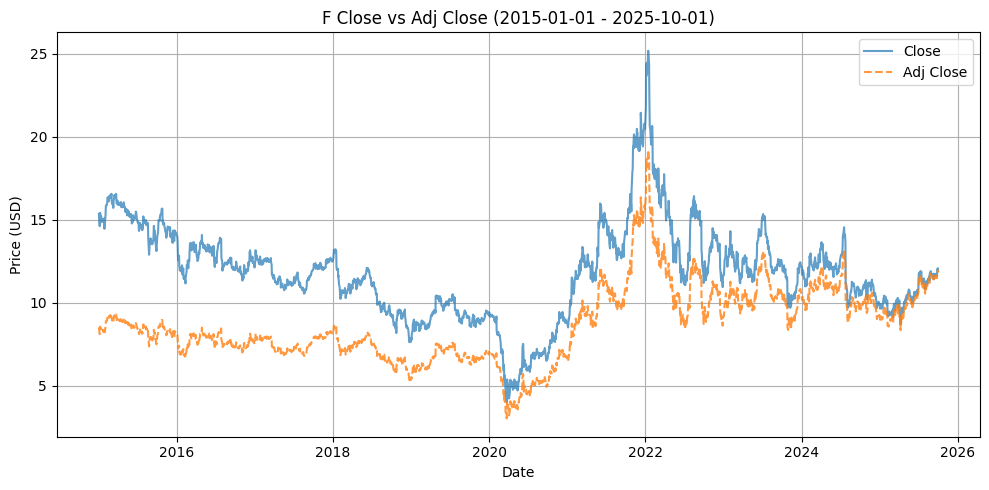

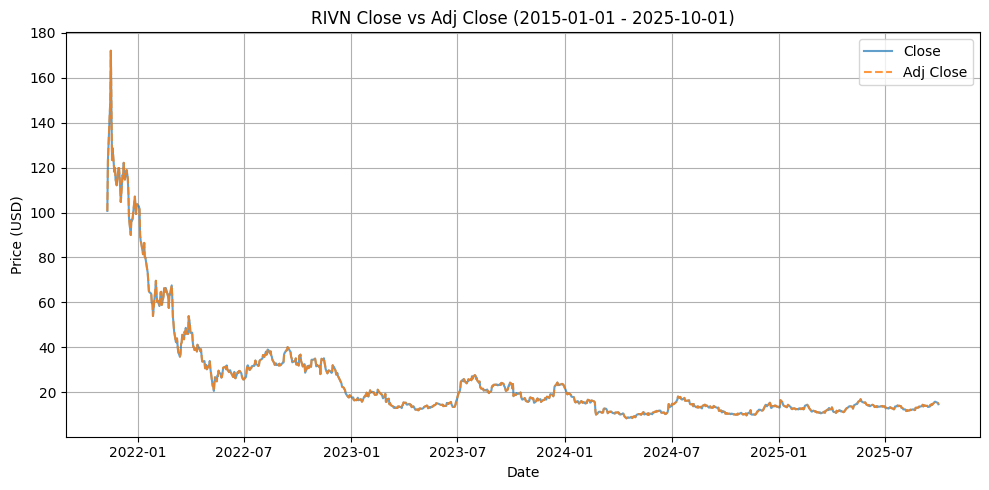

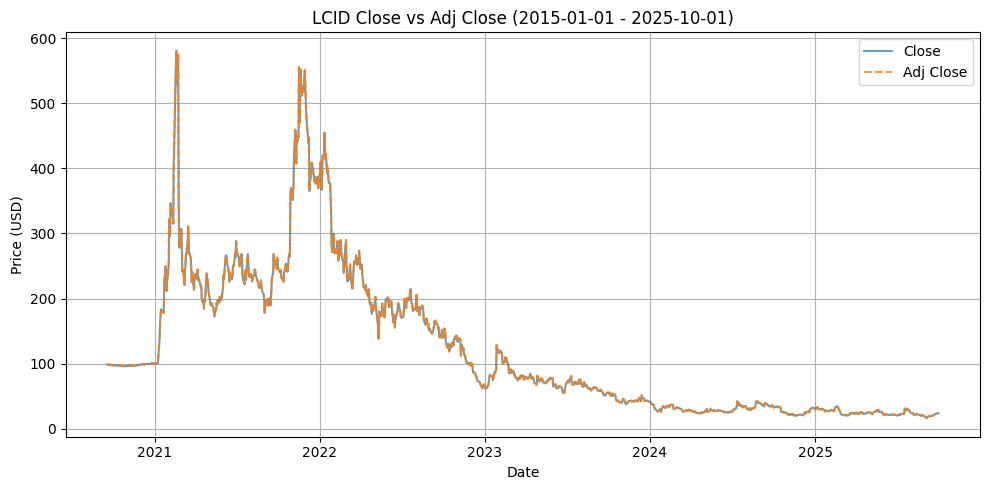

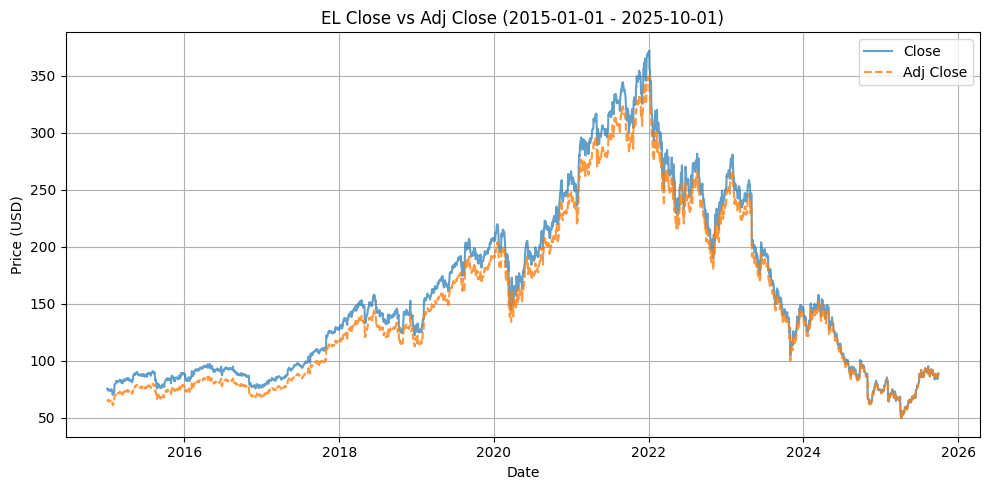

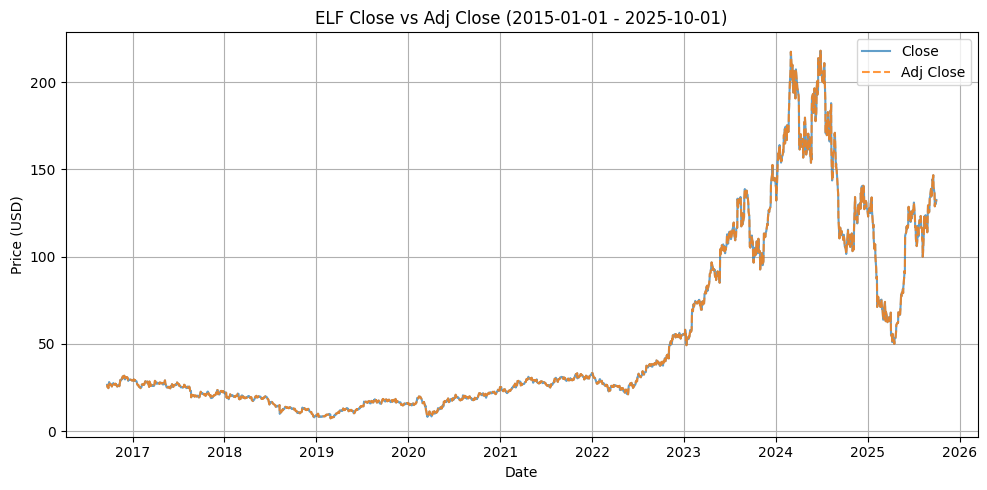

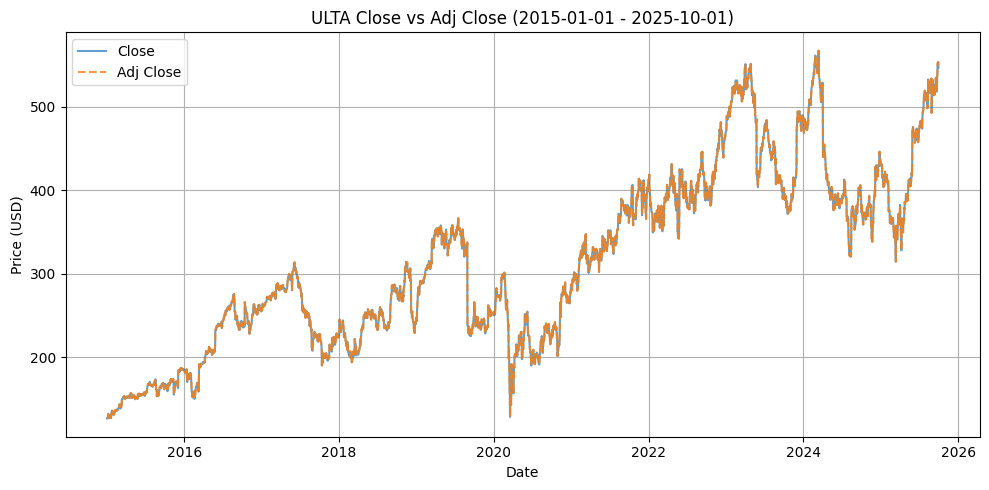

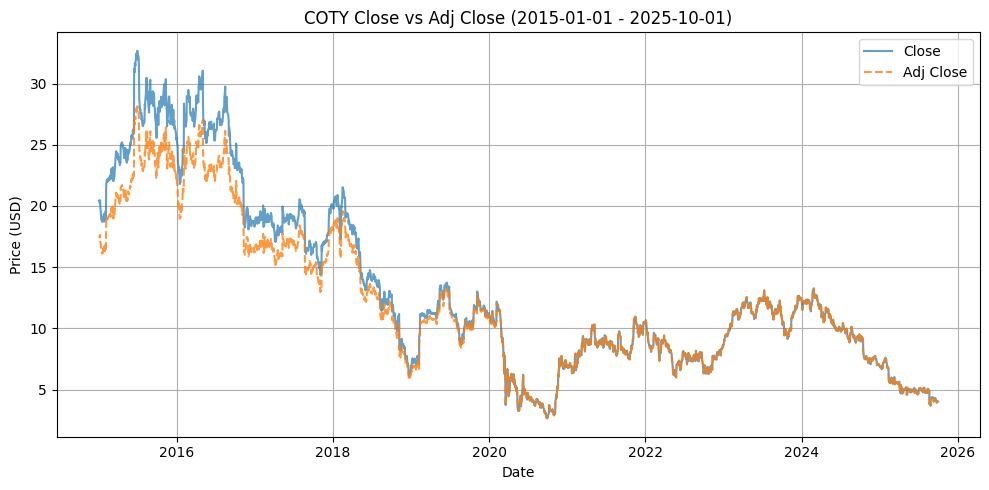

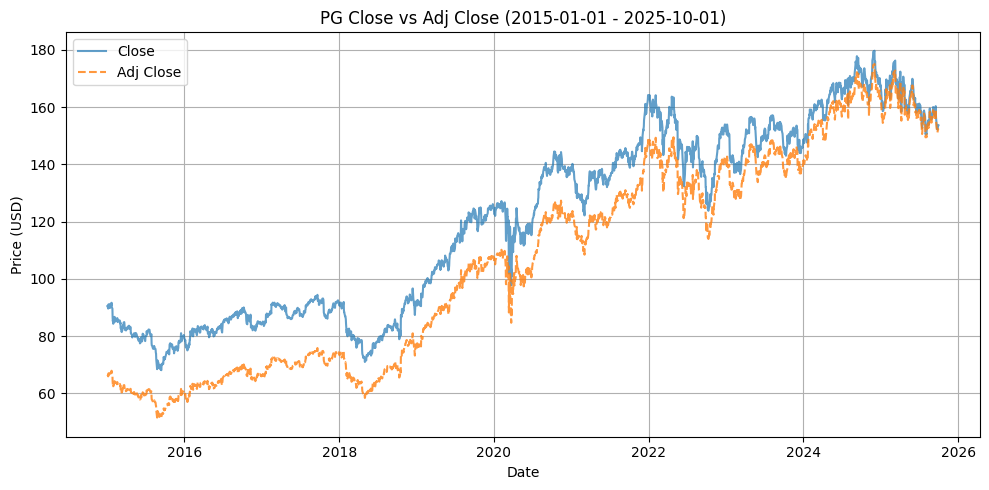

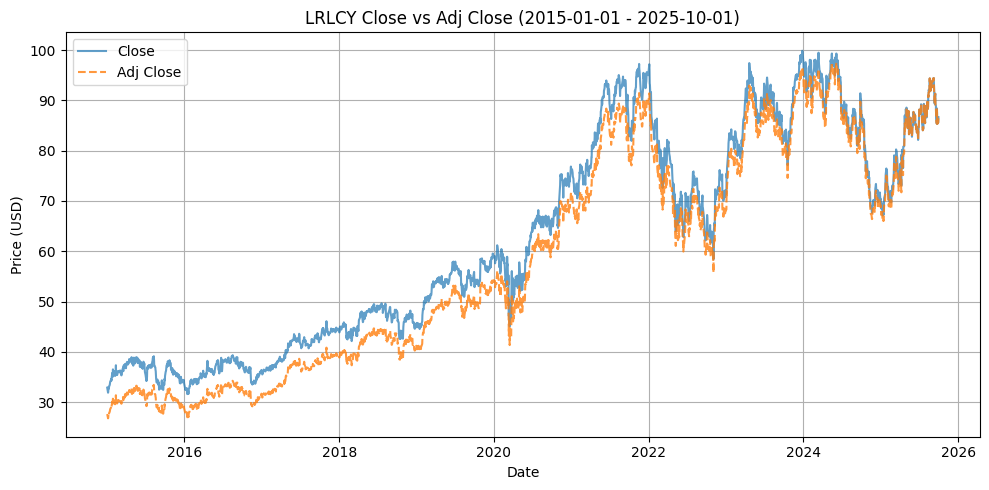

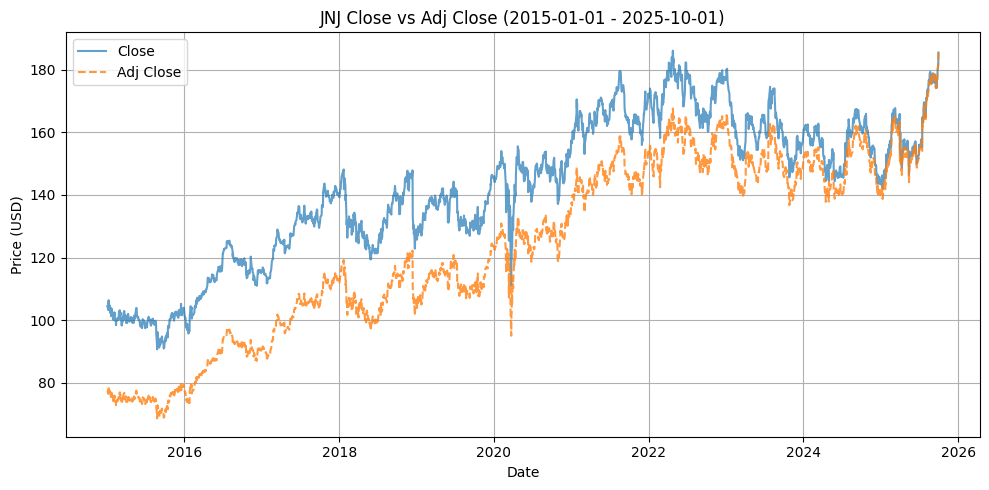

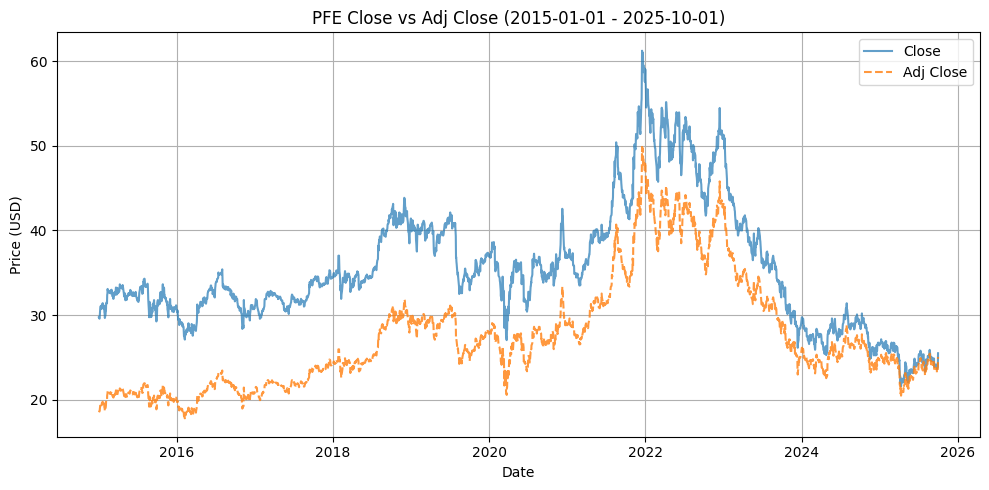

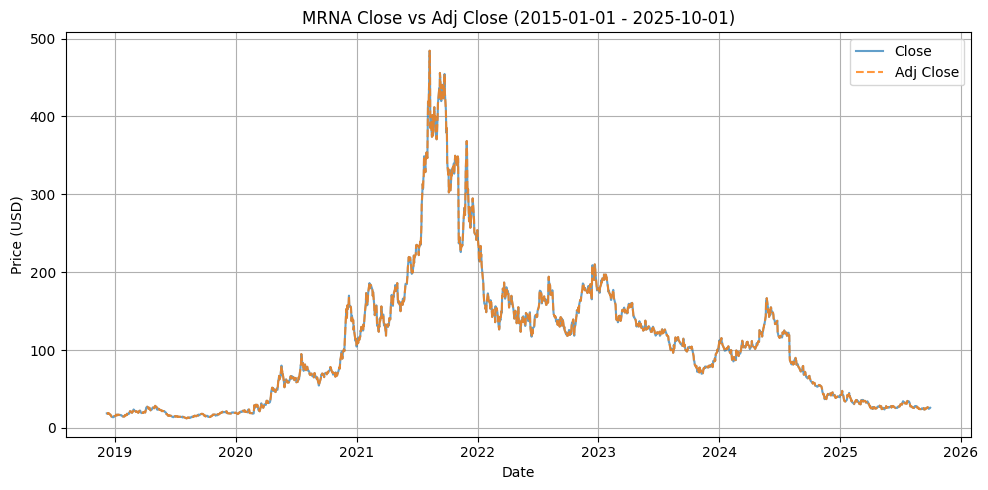

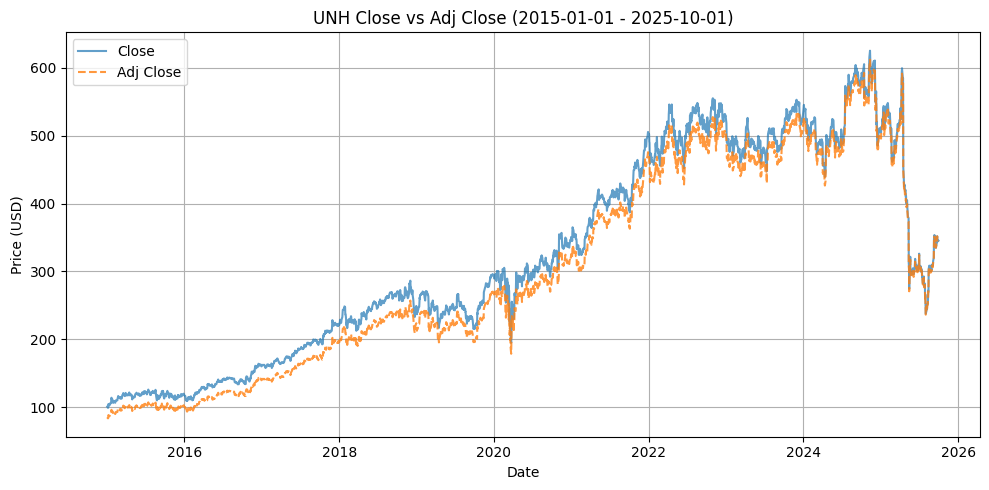

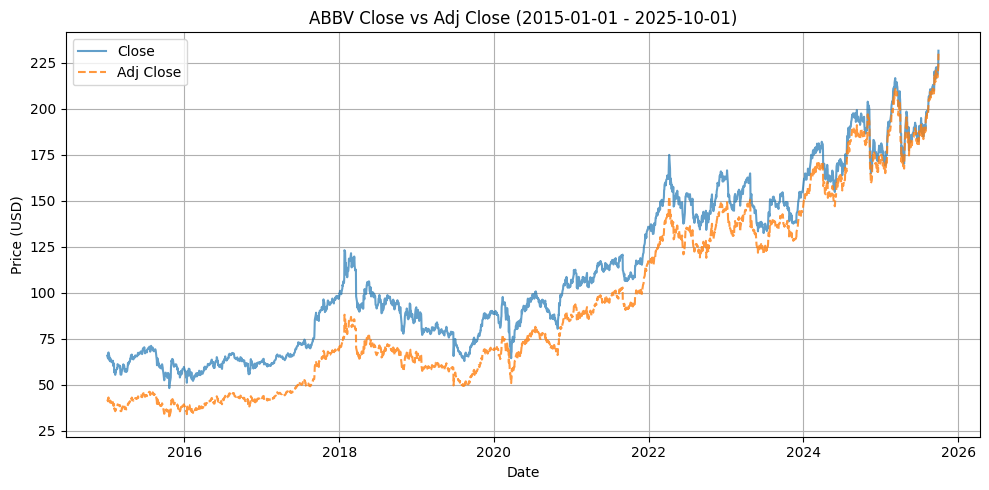

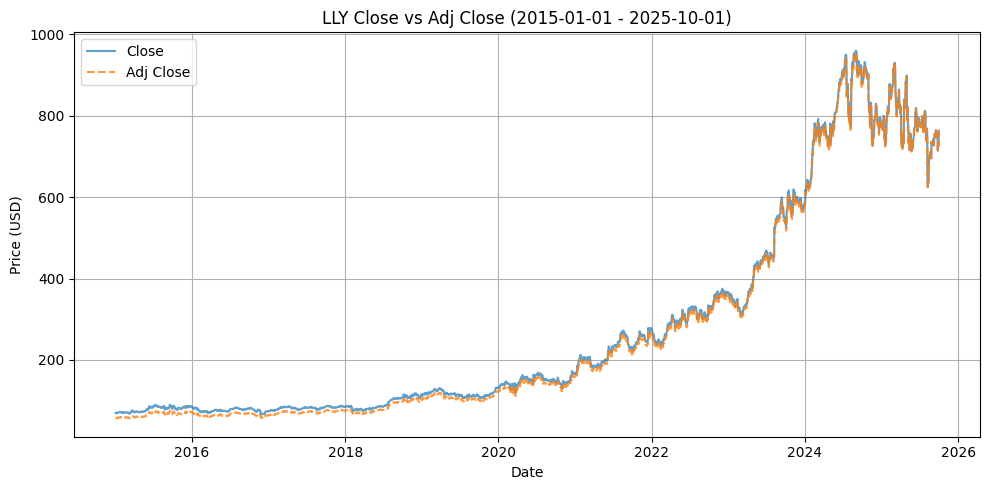

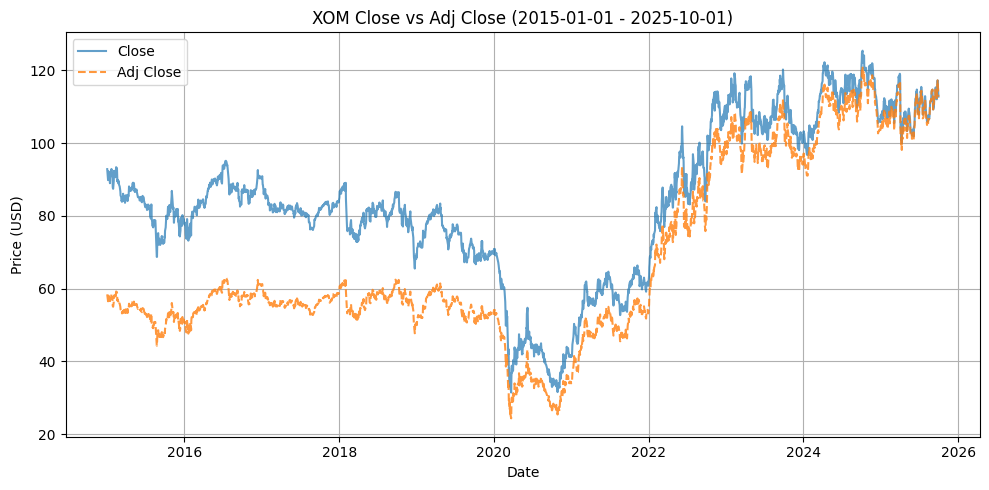

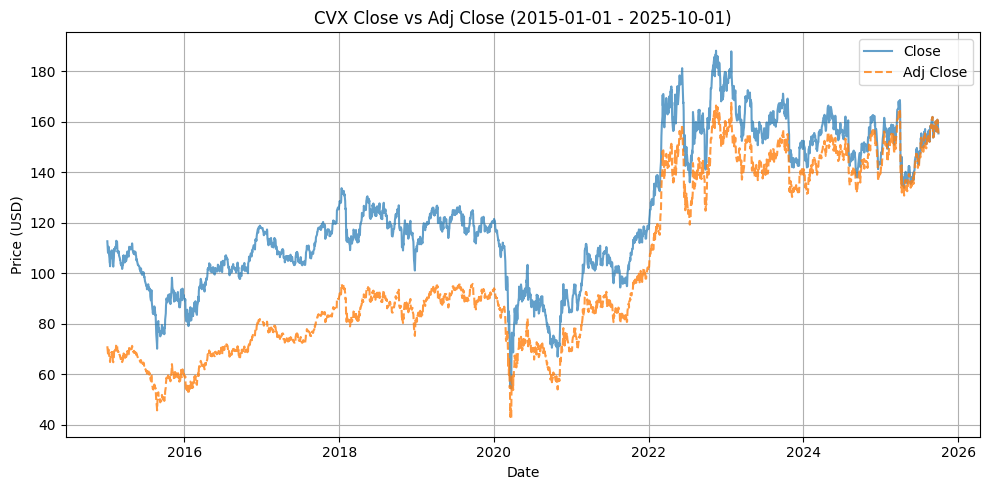

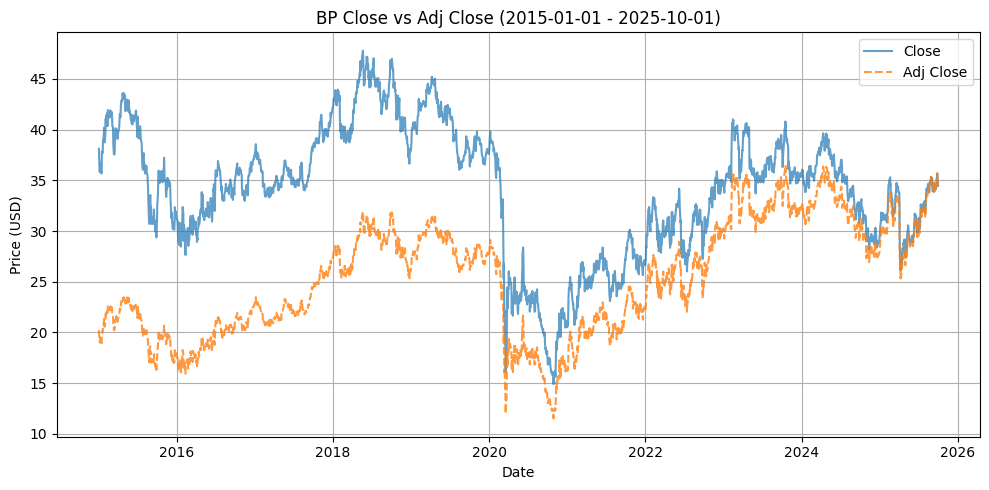

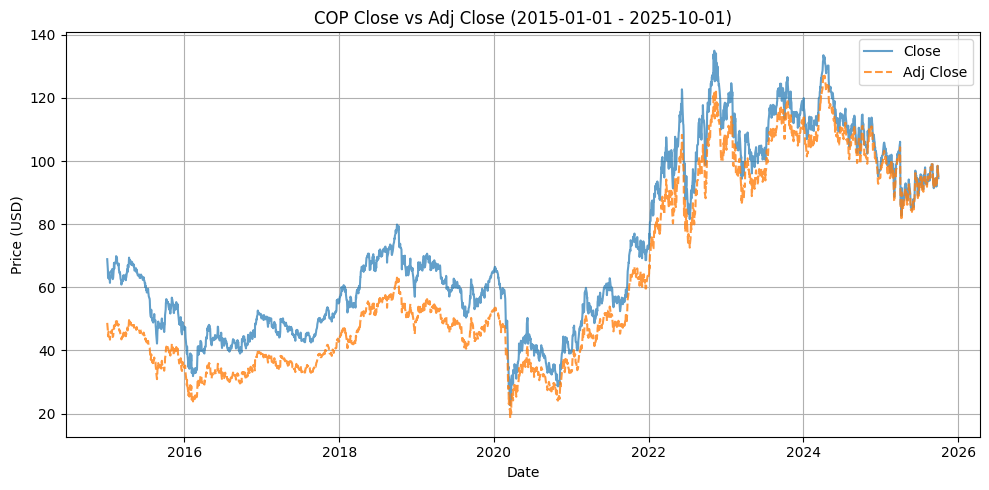

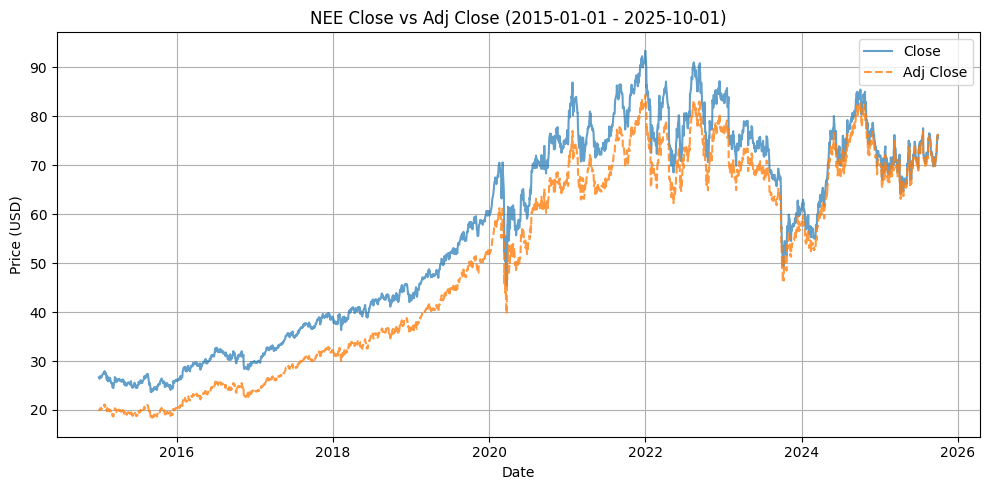

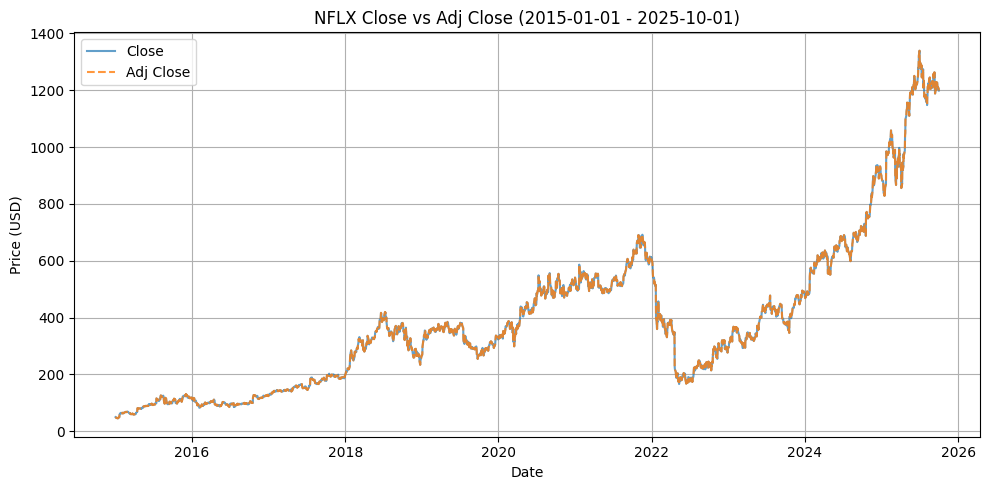

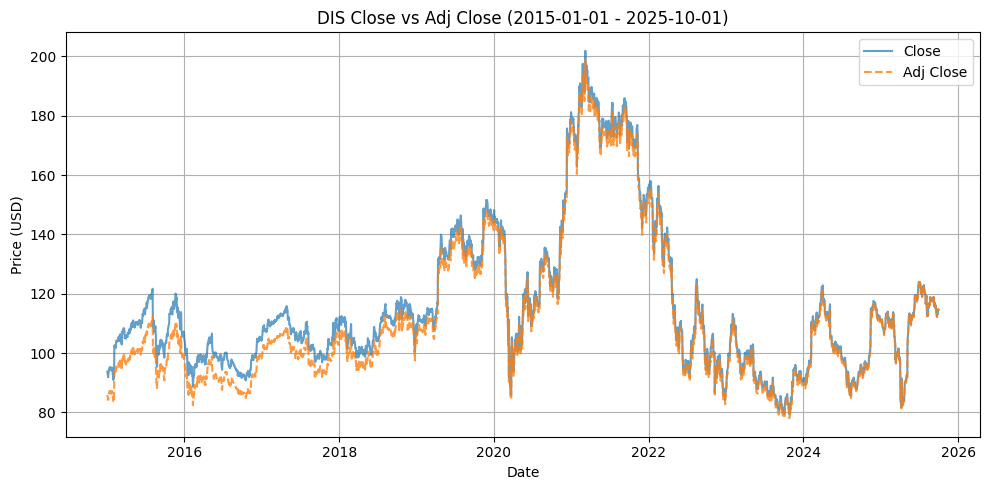

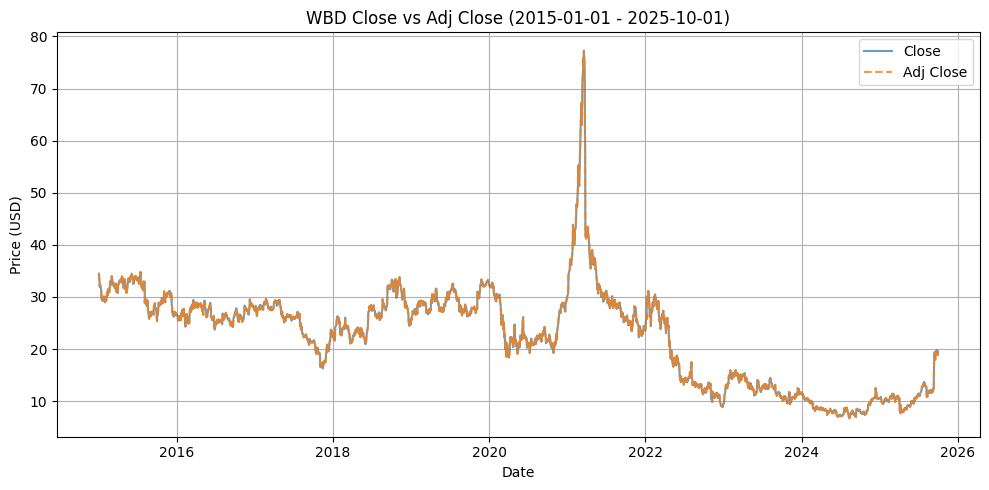

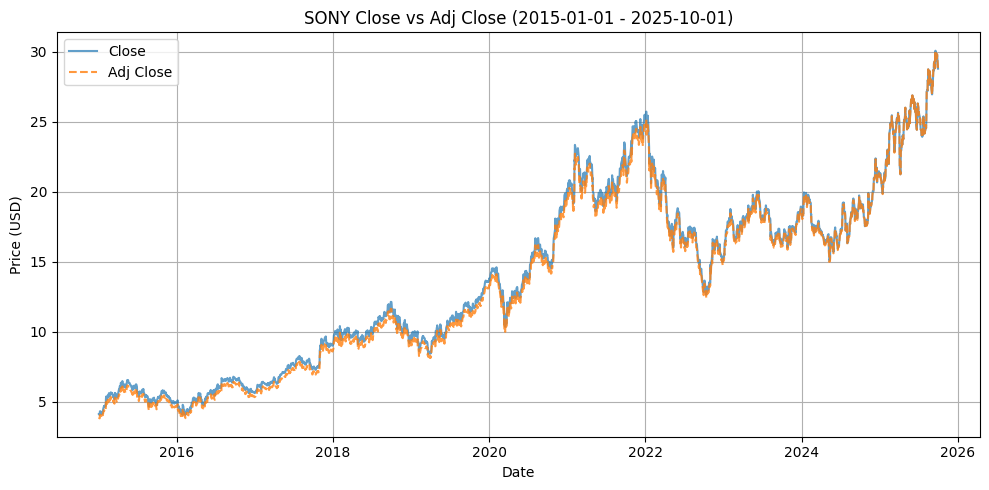

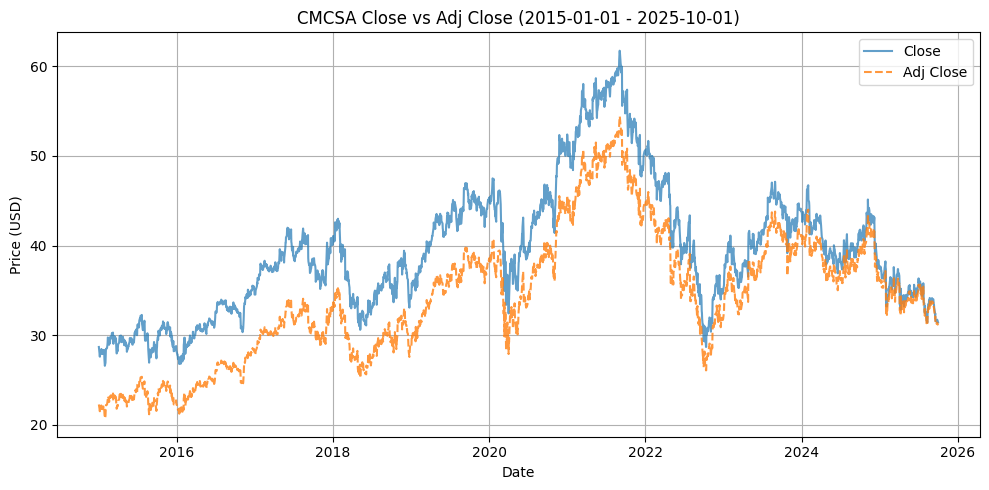

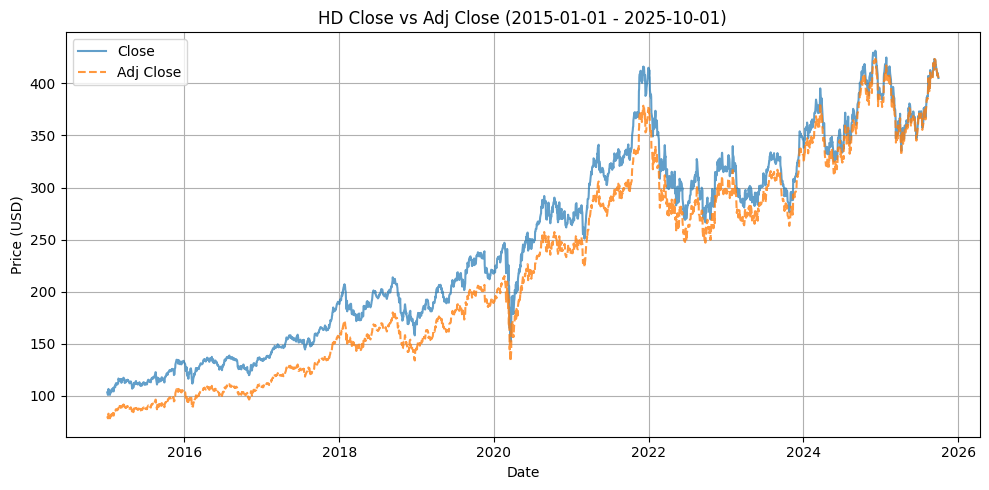

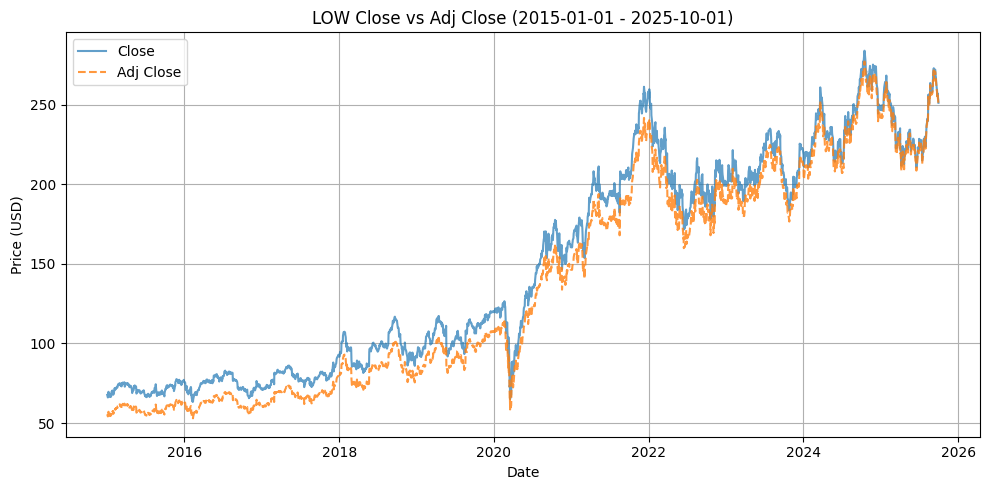

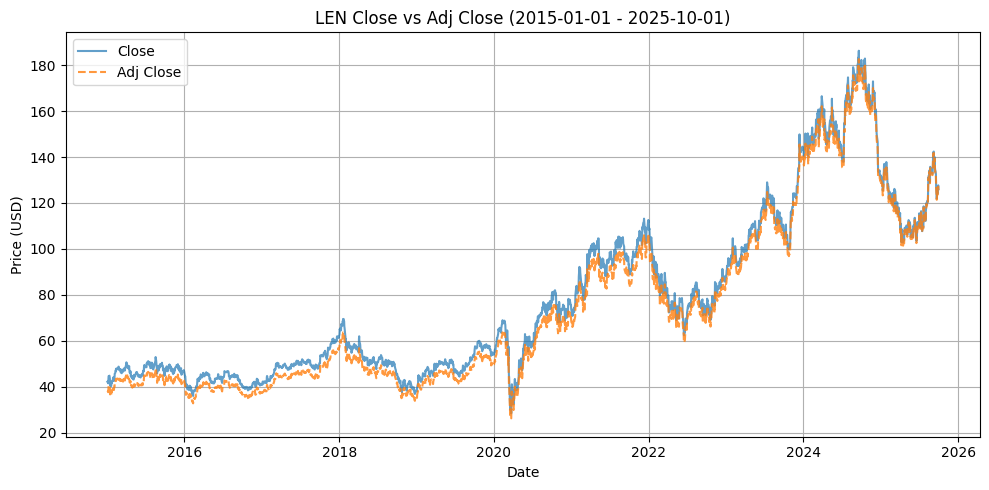

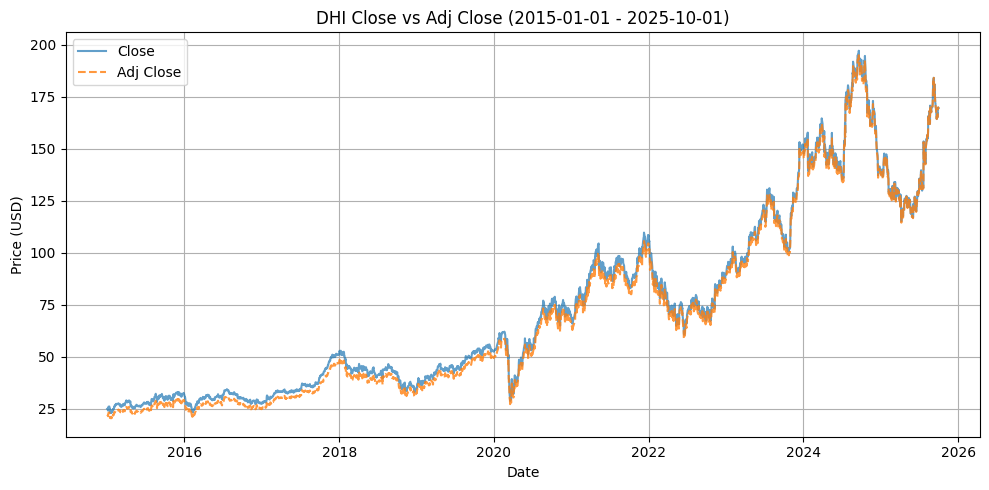

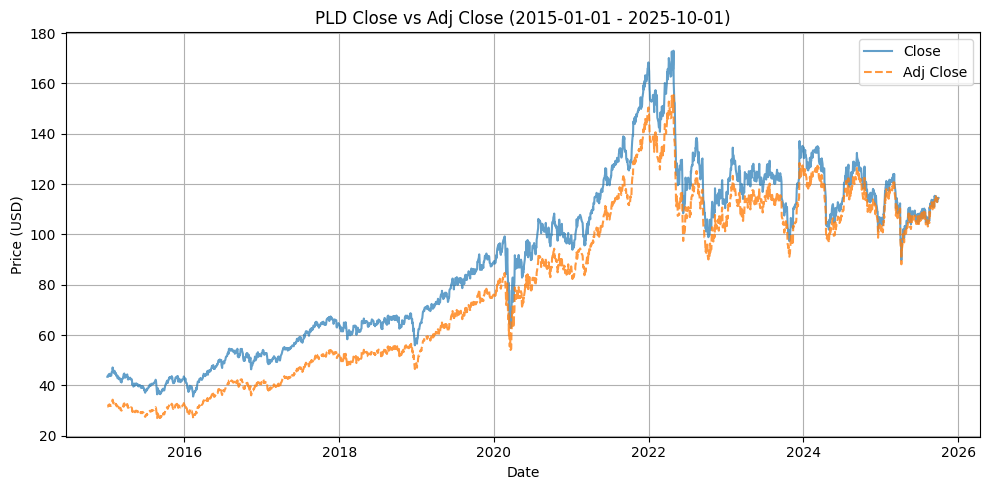

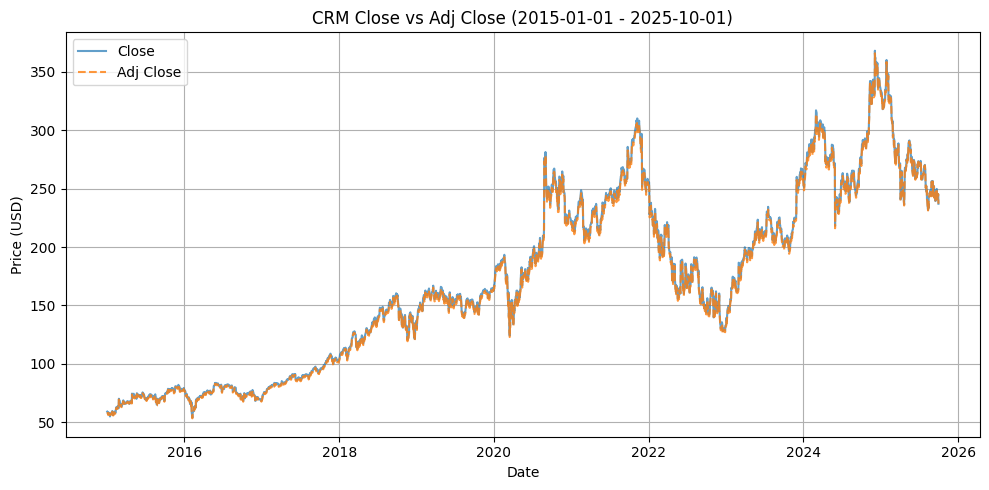

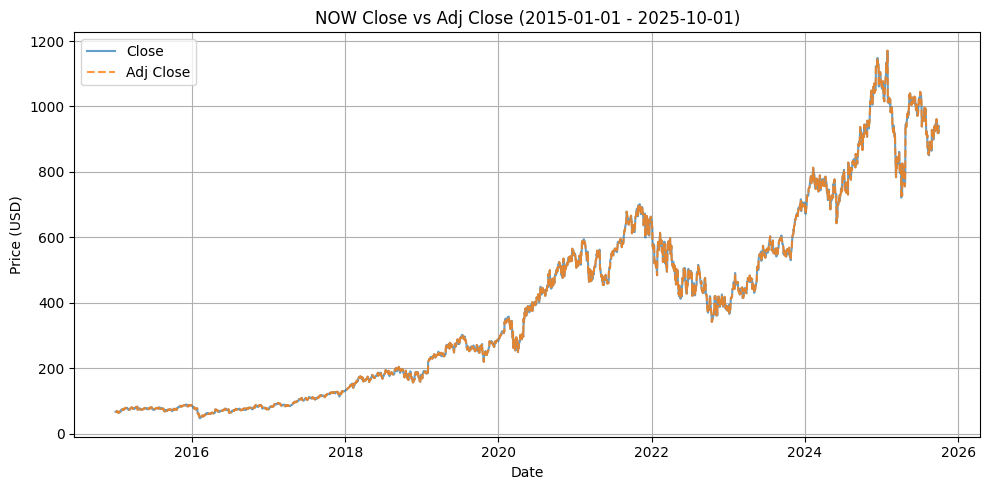

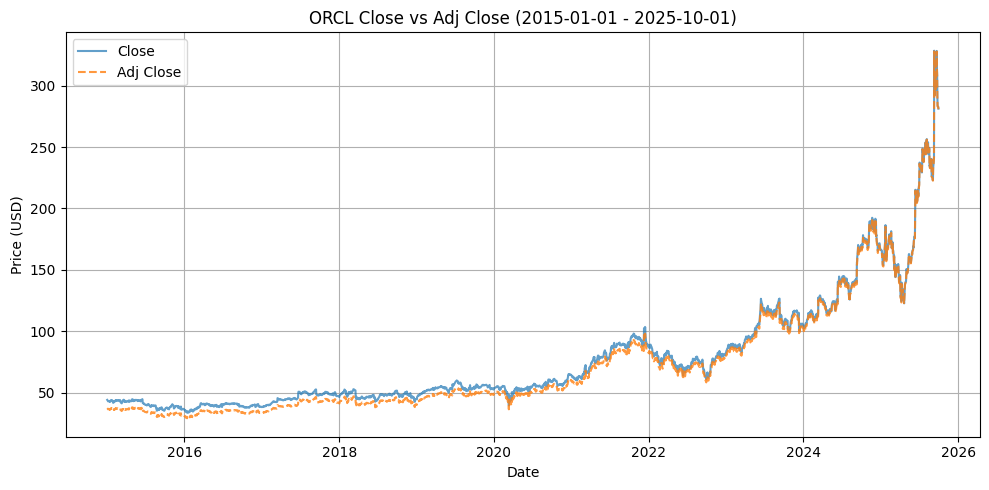

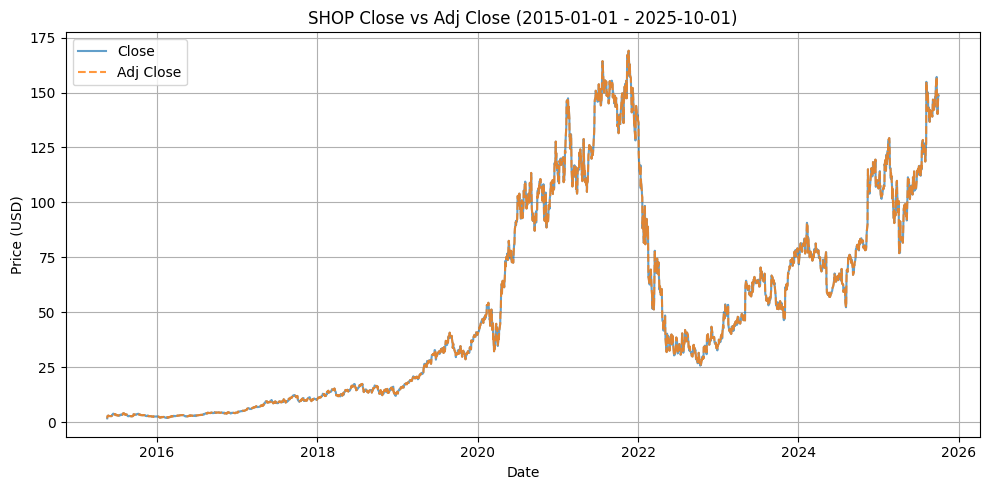

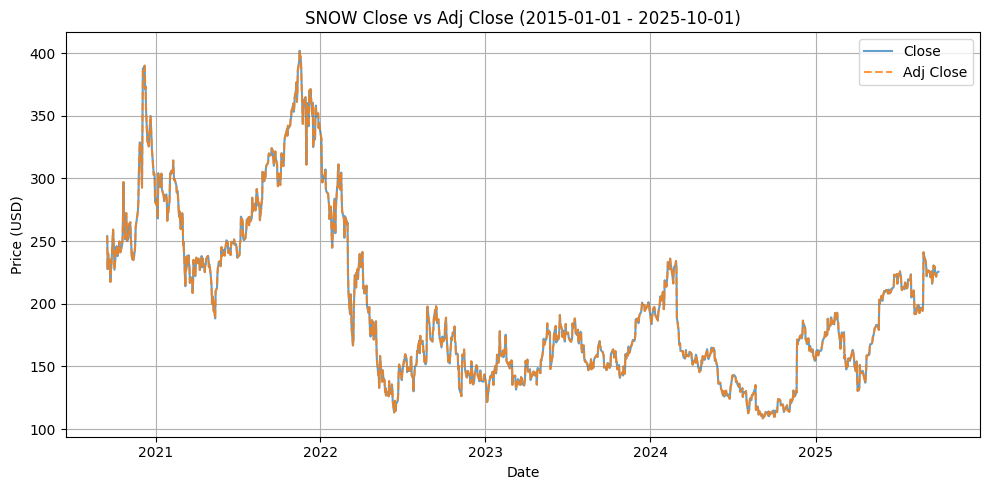

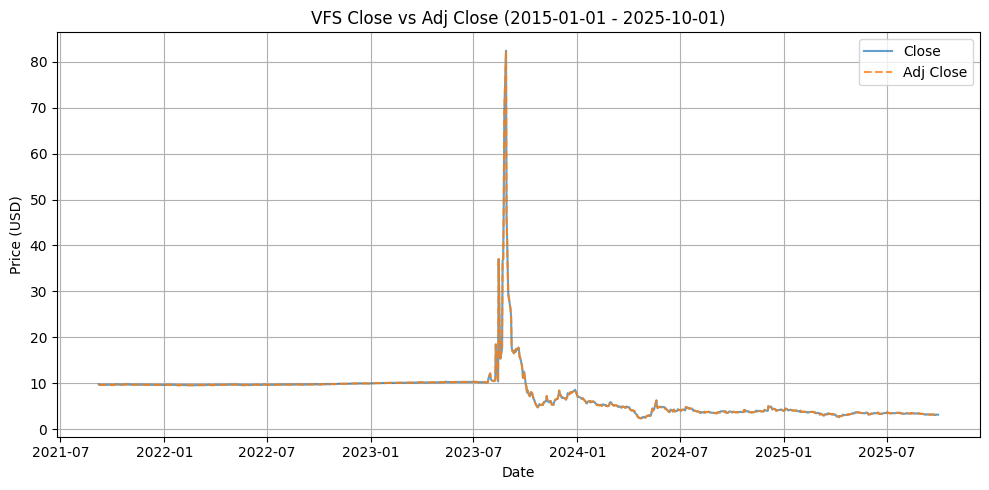

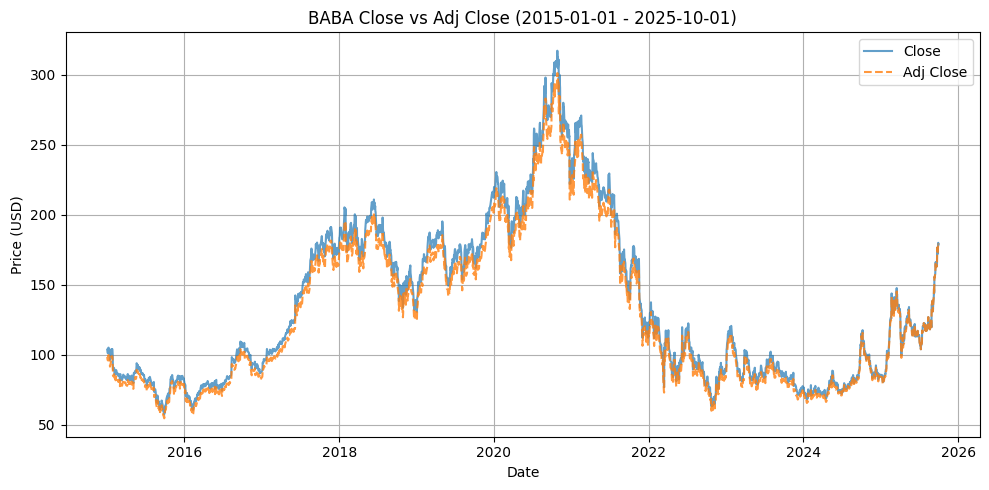

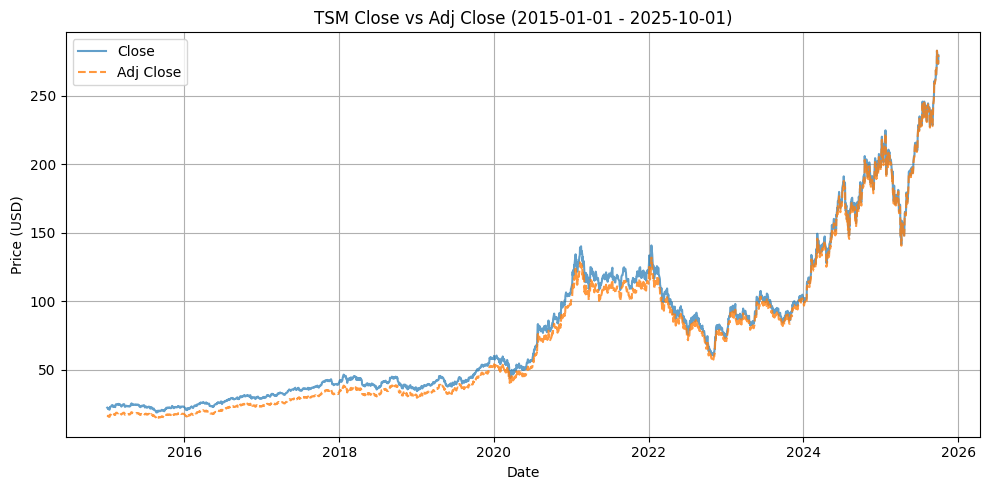

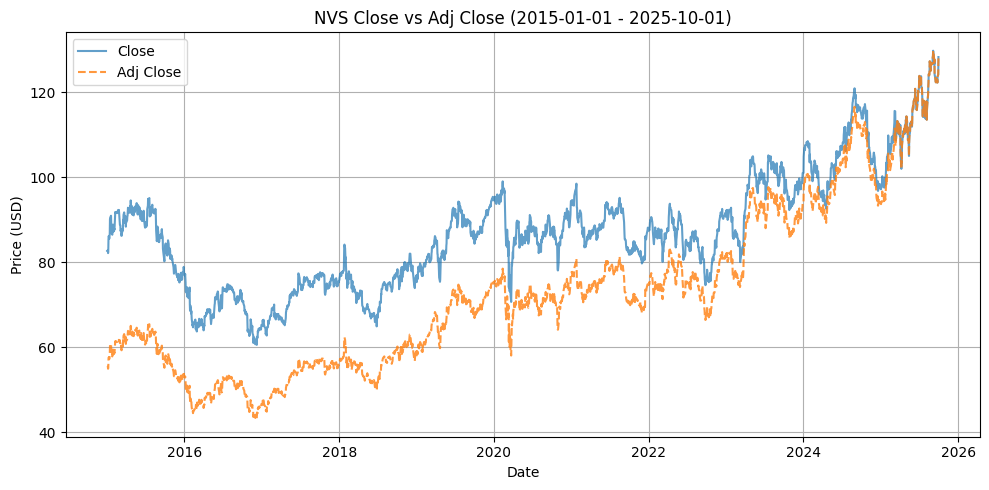

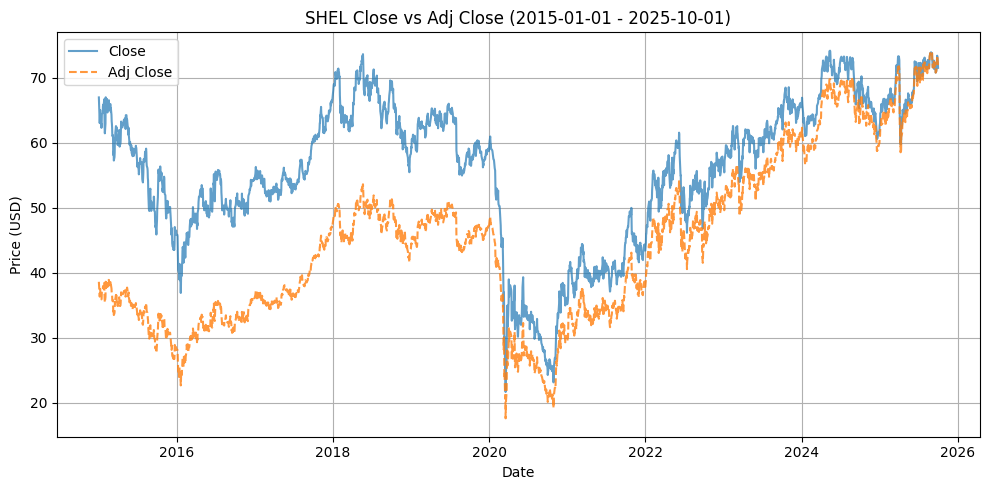

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import os

# Tạo thư mục lưu hình nếu chưa có
os.makedirs("Stock_Plots", exist_ok=True)

# Danh sách mã cổ phiếu
symbols = ['AAPL', 'MSFT', 'GOOG', 'META', 'AMZN', 'NVDA', 'TSLA', 'AMD', 'INTC', 'ADBE',
           'JPM', 'BAC', 'GS', 'MS', 'V', 'MA', 'PYPL',
           'WMT', 'TGT', 'COST', 'NKE', 'SBUX', 'MCD', 'KO', 'PEP',
           'GM', 'F', 'RIVN', 'LCID',
           'EL', 'ELF', 'ULTA', 'COTY', 'PG', 'LRLCY',
           'JNJ', 'PFE', 'MRNA', 'UNH', 'ABBV', 'LLY',
           'XOM', 'CVX', 'BP', 'COP', 'NEE',
           'NFLX', 'DIS', 'WBD', 'SONY', 'CMCSA',
           'HD', 'LOW', 'LEN', 'DHI', 'PLD',
           'CRM', 'NOW', 'ORCL', 'SHOP', 'SNOW',
           'VFS', 'BABA', 'TSM', 'NVS', 'SHEL']

start_date = '2015-01-01'
end_date = '2025-10-01'

file_path = "Stocks_MultiSheet_(1_1_2015 to 1_10_2025).xlsx"
summary_data = []

with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
    for sym in symbols:
        df = yf.download(sym, start=start_date, end=end_date, progress=False, auto_adjust=False)

        if not df.empty:
            # Giữ lại cột Adj Close (giá đã điều chỉnh)
            df = df[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']]

            # Ghi dữ liệu vào sheet riêng
            df.to_excel(writer, sheet_name=sym)

            # Tạo summary cho sheet này
            increase_pct = (df['Adj Close'].iloc[-1] - df['Adj Close'].iloc[0]) / df['Adj Close'].iloc[0] * 100
            summary = {
                'Symbol': sym,
                'Adj Close Mean': df['Adj Close'].mean(),
                'Adj Close Max': df['Adj Close'].max(),
                'Adj Close Min': df['Adj Close'].min(),
                'Adj Close Std': df['Adj Close'].std(),
                'Total Volume': df['Volume'].sum(),
                'Increase (%)': increase_pct
            }
            summary_data.append(summary)

            # Vẽ biểu đồ Close và Adj Close
            plt.figure(figsize=(10,5))
            plt.plot(df.index, df['Close'], label='Close', alpha=0.7)
            plt.plot(df.index, df['Adj Close'], label='Adj Close', linestyle='--', alpha=0.8)
            plt.title(f'{sym} Close vs Adj Close ({start_date} - {end_date})')
            plt.xlabel('Date')
            plt.ylabel('Price (USD)')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()  # Hiển thị trong notebook
            plt.savefig(f'Stock_Plots/{sym}_Close_AdjClose.png')  # Lưu hình
            plt.close()

    # Ghi summary vào sheet tổng hợp
    if summary_data:
        summary_df = pd.DataFrame(summary_data)
        summary_df.to_excel(writer, sheet_name="Summary", index=False)

# Tải file Excel về máy
files.download(file_path)


## **Technical indicators and Alpha signal**

### Biến file excel thành data frame

In [2]:
# Tạo file csv
# Import file dữ liệu excel đã tạo, chuyển thành file csv
!pip install openpyxl
import pandas as pd
from google.colab import files
import io
from scipy.stats.mstats import winsorize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [3]:
uploaded = files.upload()
file_name = next(iter(uploaded)) # Lấy tên file đã upload

Saving Stocks_MultiSheet_(1_1_2015 to 1_10_2025).xlsx to Stocks_MultiSheet_(1_1_2015 to 1_10_2025) (1).xlsx


In [29]:
# Đọc tất cả các sheets. Kết quả là một dictionary {tên_sheet: DataFrame}
# Nếu bạn dùng files.upload() (byte data), hãy dùng io.BytesIO(uploaded[file_name])
# Nếu bạn dùng Google Drive (đường dẫn), hãy dùng file_name
try:
    if 'uploaded' in locals() or 'uploaded' in globals(): # Kiểm tra xem đã upload file chưa
        xls_dict = pd.read_excel(io.BytesIO(uploaded[file_name]), sheet_name=None)
    else:
        xls_dict = pd.read_excel(file_name, sheet_name=None)
except Exception as e:
    print(f"Lỗi khi đọc file Excel: {e}")
    # Xử lý trường hợp không tìm thấy file nếu dùng Google Drive
    # hoặc file_name không đúng nếu dùng files.upload()
    exit()

# Lặp qua dictionary và lưu từng DataFrame thành file CSV
for sheet_name, df in xls_dict.items():
    # Tên file CSV sẽ là tên sheet (mã cổ phiếu)
    csv_file_name = f'{sheet_name}.csv'

    # Sử dụng .to_csv để xuất DataFrame thành file CSV
    # index=False để không bao gồm chỉ mục (index) của DataFrame vào file CSV
    df.to_csv(csv_file_name, index=False, encoding='utf-8')

In [30]:
import pandas as pd
import glob

# Đọc tất cả file CSV trong thư mục hiện tại
csv_files = glob.glob("*.csv")

dataframes = {}

for file in csv_files:
    # Lấy tên mã cổ phiếu từ tên file (VD: GOOG.csv -> GOOG)
    ticker = file.split(".")[0]

    # Đọc file, bỏ 2 hàng đầu tiên, và dùng hàng thứ 3 làm header
    df = pd.read_csv(file, skiprows=2, header=0)

    # Đổi tên cột 'Price' -> 'Date' (nếu có)
    if 'Price' in df.columns:
        df.rename(columns={'Price': 'Date'}, inplace=True)

    # Lưu DataFrame vào dictionary
    dataframes[ticker] = df

In [31]:
import pandas as pd
import glob

csv_files = glob.glob("*.csv")
dataframes = {}

for file in csv_files:
    ticker = file.split(".")[0]

    # Đọc file, bỏ 3 hàng đầu (Price, Ticker, header trống)
    df = pd.read_csv(file, skiprows=3, header=None)

    # Tự đặt lại header chuẩn
    df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

    # Lưu lại vào dict
    dataframes[ticker] = df

# ✅ Kiểm tra
print(dataframes["GOOG"].head())

                  Date       Open       High        Low      Close  Adj Close  \
0  2015-01-02 00:00:00  26.378078  26.490770  26.133251  26.168653  25.990791   
1  2015-01-05 00:00:00  26.091366  26.144720  25.582764  25.623152  25.448999   
2  2015-01-06 00:00:00  25.679497  25.738087  24.983908  25.029282  24.859165   
3  2015-01-07 00:00:00  25.280592  25.292759  24.914099  24.986401  24.816572   
4  2015-01-08 00:00:00  24.831326  25.105074  24.482782  25.065184  24.894823   

     Volume  
0  28951268  
1  41196796  
2  57998800  
3  41301082  
4  67071641  


### 1. Simple Moving Averages:
- Khi đường trung bình ngắn hạn (MA ngắn) vượt lên đường trung bình dài hạn (MA dài) $⇒$ xu hướng tăng $⇒$ MUA.
- Khi MA ngắn hạn cắt xuống MA dài hạn $⇒$ xu hướng giảm $⇒$ BÁN.

**VD:** MA ngắn (ví dụ 20 ngày) phản ứng nhanh với giá hiện tại.

MA dài (ví dụ 50 ngày) phản ứng chậm hơn.

Khi MA ngắn vượt MA dài, chứng tỏ giá đang tăng nhanh hơn xu hướng trung bình => tín hiệu mua (golden cross).

Khi ngược lại, ta có bán (death cross)

In [32]:
# Tạo 1 data frame copy
df_copy = dataframes.copy()
# In thử 1 mã cổ phiếu để kiểm tra
df_copy["AAPL"]

,Date,Open,High,Low,Close,Adj Close,Volume
0,2015-01-02 00:00:00,27.847500,27.860001,26.837500,27.332500,24.261040,212818400
1,2015-01-05 00:00:00,27.072500,27.162500,26.352501,26.562500,23.577568,257142000
2,2015-01-06 00:00:00,26.635000,26.857500,26.157499,26.565001,23.579798,263188400
3,2015-01-07 00:00:00,26.799999,27.049999,26.674999,26.937500,23.910437,160423600
4,2015-01-08 00:00:00,27.307501,28.037500,27.174999,27.972500,24.829132,237458000
...,...,...,...,...,...,...,...
2697,2025-09-24 00:00:00,255.220001,255.740005,251.039993,252.309998,252.309998,42303700
2698,2025-09-25 00:00:00,253.210007,257.170013,251.710007,256.869995,256.869995,55202100
2699,2025-09-26 00:00:00,254.100006,257.600006,253.779999,255.460007,255.460007,46076300
2700,2025-09-29 00:00:00,254.559998,255.000000,253.009995,254.429993,254.429993,40127700


In [26]:
for ticker, df in df_copy.items():

    # Ghi lại chỉ mục (index) cũ
    original_index = df.index
    df = df.reset_index() # Đưa chỉ mục Date về thành cột

    # 1. Chắc chắn chuyển đổi kiểu dữ liệu (lặp lại)
    df['Close'] = pd.to_numeric(df['Close'], errors='coerce')

    # 2. Tính toán SMA trên Series không có chỉ mục Date phức tạp
    df['SMA_20'] = df['Close'].rolling(window=20).mean()

    # Đặt lại chỉ mục Date gốc
    df = df.set_index(original_index.name)

    df_copy[ticker] = df

KeyError: 'None of [None] are in the columns'

In [43]:
df_copy["AAPL"]["Adj Close"].rolling(window=50).mean().head(30)

,Adj Close
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN


In [39]:
# Kiểm tra lại các bước:
for ticker, df in df_copy.items():
    # Bước 1: Loại bỏ các giá trị không phải số (NaN) nếu có, sau khi chuyển đổi
    # (Nếu có NaN, Pandas vẫn bỏ qua, nhưng kiểm tra có thể hữu ích)
    price_series = pd.to_numeric(df['Close'], errors='coerce')

    # Bước 2: Tính toán
    df['SMA_20'] = price_series.rolling(window=20).mean()

    df_copy[ticker] = df

In [40]:
import pandas as pd
import numpy as np
# Tính Moving Average của cột Adj_Close trong 1 cửa sổ cố định (20 ngày hoặc 50 ngày)
# 1. Lặp qua Dictionary và Tính toán SMA
# Lặp qua key (mã cổ phiếu) và value (DataFrame)
for ticker, df in df_copy.items():

    # Tính bằng cột 'Adj Close'
    price_column = 'Adj Close'

    # Tính SMA 20 kỳ
    df['SMA_20'] = df[price_column].rolling(window=20).mean()

    # Tính SMA 50 kỳ
    df['SMA_50'] = df[price_column].rolling(window=50).mean()

    # Cập nhật lại DataFrame đã tính toán vào dictionary
    df_copy[ticker] = df

# 3. Hiển thị kết quả (Ví dụ cho mã INTC)
print("--- Kết quả tính SMA cho INTC ---")
print(df_copy['INTC'].tail(10))

DataError: No numeric types to aggregate

In [37]:
print("--- Kết quả tính SMA cho INTC ---")
print(df_copy['INTC'].tail(10))

--- Kết quả tính SMA cho INTC ---
                     Date       Open       High        Low      Close  \
2692  2025-09-17 00:00:00  25.080000  25.260000  24.450001  24.900000   
2693  2025-09-18 00:00:00  31.780001  32.380001  30.160000  30.570000   
2694  2025-09-19 00:00:00  30.379999  30.629999  29.330000  29.580000   
2695  2025-09-22 00:00:00  29.670000  30.100000  28.730000  28.760000   
2696  2025-09-23 00:00:00  28.990000  30.200001  28.820000  29.340000   
2697  2025-09-24 00:00:00  29.379999  31.700001  29.230000  31.219999   
2698  2025-09-25 00:00:00  31.610001  34.250000  31.209999  33.990002   
2699  2025-09-26 00:00:00  35.020000  36.299999  34.490002  35.500000   
2700  2025-09-29 00:00:00  34.520000  35.049999  33.730000  34.480000   
2701  2025-09-30 00:00:00  33.930000  34.240002  33.020000  33.549999   

      Adj Close     Volume  
2692  24.900000   63093700  
2693  30.570000  523908000  
2694  29.580000  225702900  
2695  28.760000  130314500  
2696  29.340000  